# From Pikes to Pageviews: Forecasting Attention Around Buckethead

I’ve spent plenty of time exploring Buckethead’s music. This project began
when that curiosity turned into a forecasting question: **how accurately could
I predict the next 28 days of daily views to his English Wikipedia page?**

If you don't know **Buckethead**, he's an American guitarist who performs in
a white mask with a KFC bucket on his head. His music ranges from extraordinary
technical playing to some of the most moving instrumental pieces I've heard.
I'm a huge fan, particularly of the **Pikes**, the numbered series of short,
guitar-led albums that began in 2011. The
[artist's catalog](https://bucketheadpikes.com/index2.html) documents those
installments within his prolific body of work.

### Why this question mattered to me

A long record of pageviews makes historical attention easy to plot. Predicting
it is harder: the usual traffic level changes, exceptional days can dominate
an average, and an interesting musical date may become meaningful only after
the attention has arrived. I wanted to see which patterns were useful before
issuing a forecast, how much a fitted model could add to recent weekday
history, and how honestly its intervals represented uncertainty.

Wikipedia traffic gives that investigation a concrete, limited target. It
records activity on one article. Understanding that boundary matters before
interpreting a forecast as evidence about an artist's wider audience.

### What I set out to investigate

The project has three connected goals: **compare complete 28-day forecasts
against demanding seasonal benchmarks**, **investigate when a selected model
fails to carry its development advantage forward**, and **test whether more
adaptive or pretrained procedures add useful evidence**. Point accuracy and
uncertainty receive separate evaluations throughout.

By following the analysis, readers will see how to:

- Define a measurable target and distinguish historical context from inputs
  that could have been known at forecast issuance.
- Turn an observation delay into a consistent forecast path and chronological
  comparison, including historical training labels.
- Use seasonal references to assess statistical models, machine learning and
  fixed pretrained forecasting recipes.
- Read signed errors, sensitivity checks, interval coverage and width without
  claiming more than the evaluation supports.

### How the investigation unfolds

I begin with the data and musical context, then establish the forecasting
rules and original comparison. The original development winner performs poorly
in the later year, prompting diagnosis and a bounded adaptive-model follow-up.
A subsequent foundation-model extension tests another source of forecasting
ability. **The later investigations reuse an already examined year**; their
results remain retrospective evidence.

The notebook follows those stages in order, with intermediate checkpoints and
a final synthesis covering the complete project. Saved figures, tables and
selected implementation excerpts support the reasoning. The executed cells
read and verify the recorded experiments; normal notebook execution does not
refit or call forecasting models. The
[reproduction guide](docs/reproducibility.md) separates those reader checks
from optional experiment replay.


## 1. Measuring attention to one Wikipedia page

Before building a forecasting model, I needed to be precise about what I was trying to predict and what the available data could tell me.

### 1.1. Defining the target

The target is **daily user-classified pageviews of Buckethead's English Wikipedia article**, using the canonical title `Buckethead`.

I use Wikimedia's `all-access` counts and verify that they equal the sum of **desktop, mobile-web, and mobile-app** counts. These categories describe how the article was accessed.

Pageviews are not unique readers or a count of fans. One person can visit several times, while someone who listens to Buckethead regularly might never open his Wikipedia page. “User-classified” describes Wikimedia's traffic classification, rather than identifying distinct people.

Throughout this notebook, *attention* therefore means **recorded, user-classified traffic to this particular page**, rather than Buckethead's overall popularity. The [Wikimedia pageview documentation](https://doc.wikimedia.org/generated-data-platform/aqs/analytics-api/concepts/page-views.html) provides the underlying definitions.

The title also sets a measurement boundary. This series excludes traffic separately recorded under alternative titles or redirects. A redirect's destination today does not establish where it pointed throughout the historical period, so current redirect mappings cannot reliably reconstruct all historical title traffic.

### 1.2. Checking the saved history

The snapshot contains **4,141 consecutive daily observations**, from **July 1, 2015, through October 31, 2026**.

The acquisition checks found:

- **No missing canonical dates:** every calendar day has an observation.
- **No duplicate canonical dates:** each date appears once.
- **Exact access-method reconciliation:** desktop, mobile-web, and mobile-app counts sum to the `all-access` total.

These checks establish a continuous daily calendar and arithmetic consistency between the available series. They do not independently verify complete traffic capture or perfect classification.

I retained **every observation in the primary target**, including unusually high and low counts. An unusual value is not automatically a recording error, and deleting it could remove behavior the forecasting exercise needs to confront. Later scoring sensitivities are reported separately.

### 1.3. Historical information and evaluation boundaries

I retrieved the history after the dates being studied. The snapshot therefore contains values available at retrieval time, which may differ from earlier published versions.

At each forecast issue date `O`, the protocol permits observations only through **`O − 2`**. The intervening day, `O − 1`, remains unobserved, and no actual counts from the 28-day forecast window can enter that forecast.

This cutoff enforces the chosen information boundary. Historical data versions and publication times remain unverified, limiting how precisely the simulation reconstructs what was available at each past issuance.

For the original experiment, **model selection used development data only**. EDA ends on **November 1, 2024**, after the scored tuning period and before procedure selection. A development-only numerical preflight and the original evaluation entry point were locked before evaluating **November 2, 2025, through October 31, 2026**.

The later diagnostics, adaptive-model follow-up and foundation-model extension use that completed evaluation to **investigate the failure and examine possible improvements**. Each is identified separately in the narrative. Independent confirmation still requires previously unexamined outcomes.

### 1.4. Reading the setup outputs

The first output below records the saved delivery-integrity check: **931 files**
and **799 mapped source artifacts**. It checks the included research package;
it does not verify files omitted from the working archive or establish when an
analyst first saw the outcomes. The extended reader was subsequently executed against its current inventory;
this verification does not run forecasting models.

The next output separates **12 scored tuning paths**, **12 scored selection
paths**, and **13 final paths covering 364 days**. The additional boundary block
in each development split is deliberately unscored: its last target would not
be available by the next stage's `O − 2` cutoff. Its observations can enter later
training as they become available, but its incomplete path cannot influence
the preceding stage's score.

The original EDA window overlaps the earlier tuning period and ends before
procedure selection. This is development research informed by those data;
the schedule does not make the tuning results independent of exploration.
The first two outputs describe that original design. The foundation-model
extension later reuses its scored dates without conducting another tuning
search.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'provenance/manifest.json').exists())
P1, P2, P3, P4 = [ROOT / 'results' / name for name in
                  ('development', 'original_evaluation', 'diagnostics', 'retrospective_followup')]
sys.path.insert(0, str(ROOT / 'src'))
import integrity
import verify_saved as saved

display(pd.Series(integrity.verify_current(), name='Verified GitHub delivery'))
full_y, development, original_final, extension = saved.read_results()
y = pd.read_csv(ROOT / 'data/processed/development_daily.csv', parse_dates=['date']).set_index('date')['count']
assert y.index.max() < pd.Timestamp('2025-11-02')
config = json.loads((P1 / 'proposed_final_configuration.json').read_text())
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_colwidth', 65)

status                                                                         passed
delivery_files_verified                                                           931
mapped_source_artifacts_verified                                                  799
notebooks                                    [buckethead_wikipedia_forecasting.ipynb]
scope                               Included delivery files; omitted working-archi...
Name: Verified GitHub delivery, dtype: object

In [2]:
# Read archived EDA; do not regenerate or overwrite Phase 1 artifacts.
eda = json.loads((P1 / 'eda_summary.json').read_text())
schedule = pd.read_csv(ROOT / 'provenance/protocols/original/split_schedule.csv')
display(schedule.groupby('split')[['use_for_hyperparameter_tuning',
    'use_for_procedure_selection', 'boundary_observation_block']].sum())
display(pd.Series({'EDA ends': '2024-11-01', 'tuning scored paths': 12,
    'selection scored paths': 12, 'final paths': 13, 'primary final days': 364}))

,use_for_hyperparameter_tuning,use_for_procedure_selection,boundary_observation_block
split,,,
final,0,0,0
selection,0,12,1
tuning,12,0,1


EDA ends                  2024-11-01
tuning scored paths               12
selection scored paths            12
final paths                       13
primary final days               364
dtype: object

## 2. Weekday patterns, changing levels, and exceptional days

I first wanted to separate two forecasting difficulties: changes in the usual
traffic level and occasional days far above it. Figure 1 and the annual table
below show why both deserved attention.

Complete-year means fell from **2,316 views/day in 2016** to **1,494 in 2022**,
then rose to **1,617 in 2023**. The table labels 2015 and 2024 as partial years:
2015 begins on July 1, while this EDA sample ends on November 1, 2024. Their
means describe different calendar coverage, so I do not read the 2024 value as
a directly comparable full-year recovery.

The mean and median also tell different stories. In 2016, the mean was
**2,316.0**, the median **2,080.5**, and the maximum **24,744**. Large days pull
the mean above a more typical observed level. November 30, 2016 alone exceeds
fourteen times the pre-selection median. Later
[historical research](docs/research/diagnostics/HISTORICAL_INTERPRETATION.md)
found a same-date online discussion linking Wikipedia, providing context
without identifying the source of the traffic.

Figure 1 places raw counts and a robust weekly STL trend above a `log1p`
display of the same observations. The logarithmic view makes smaller changes
visible alongside the spikes; **all forecasting methods still use the original
count target**. The two-sided STL trend is descriptive within the EDA window.
It is neither a model feature nor a replacement target.

These observations gave me a reason to compare expanding and recent training
histories. They did not establish which history would forecast best, and I
retained every unusual observation when making that comparison.


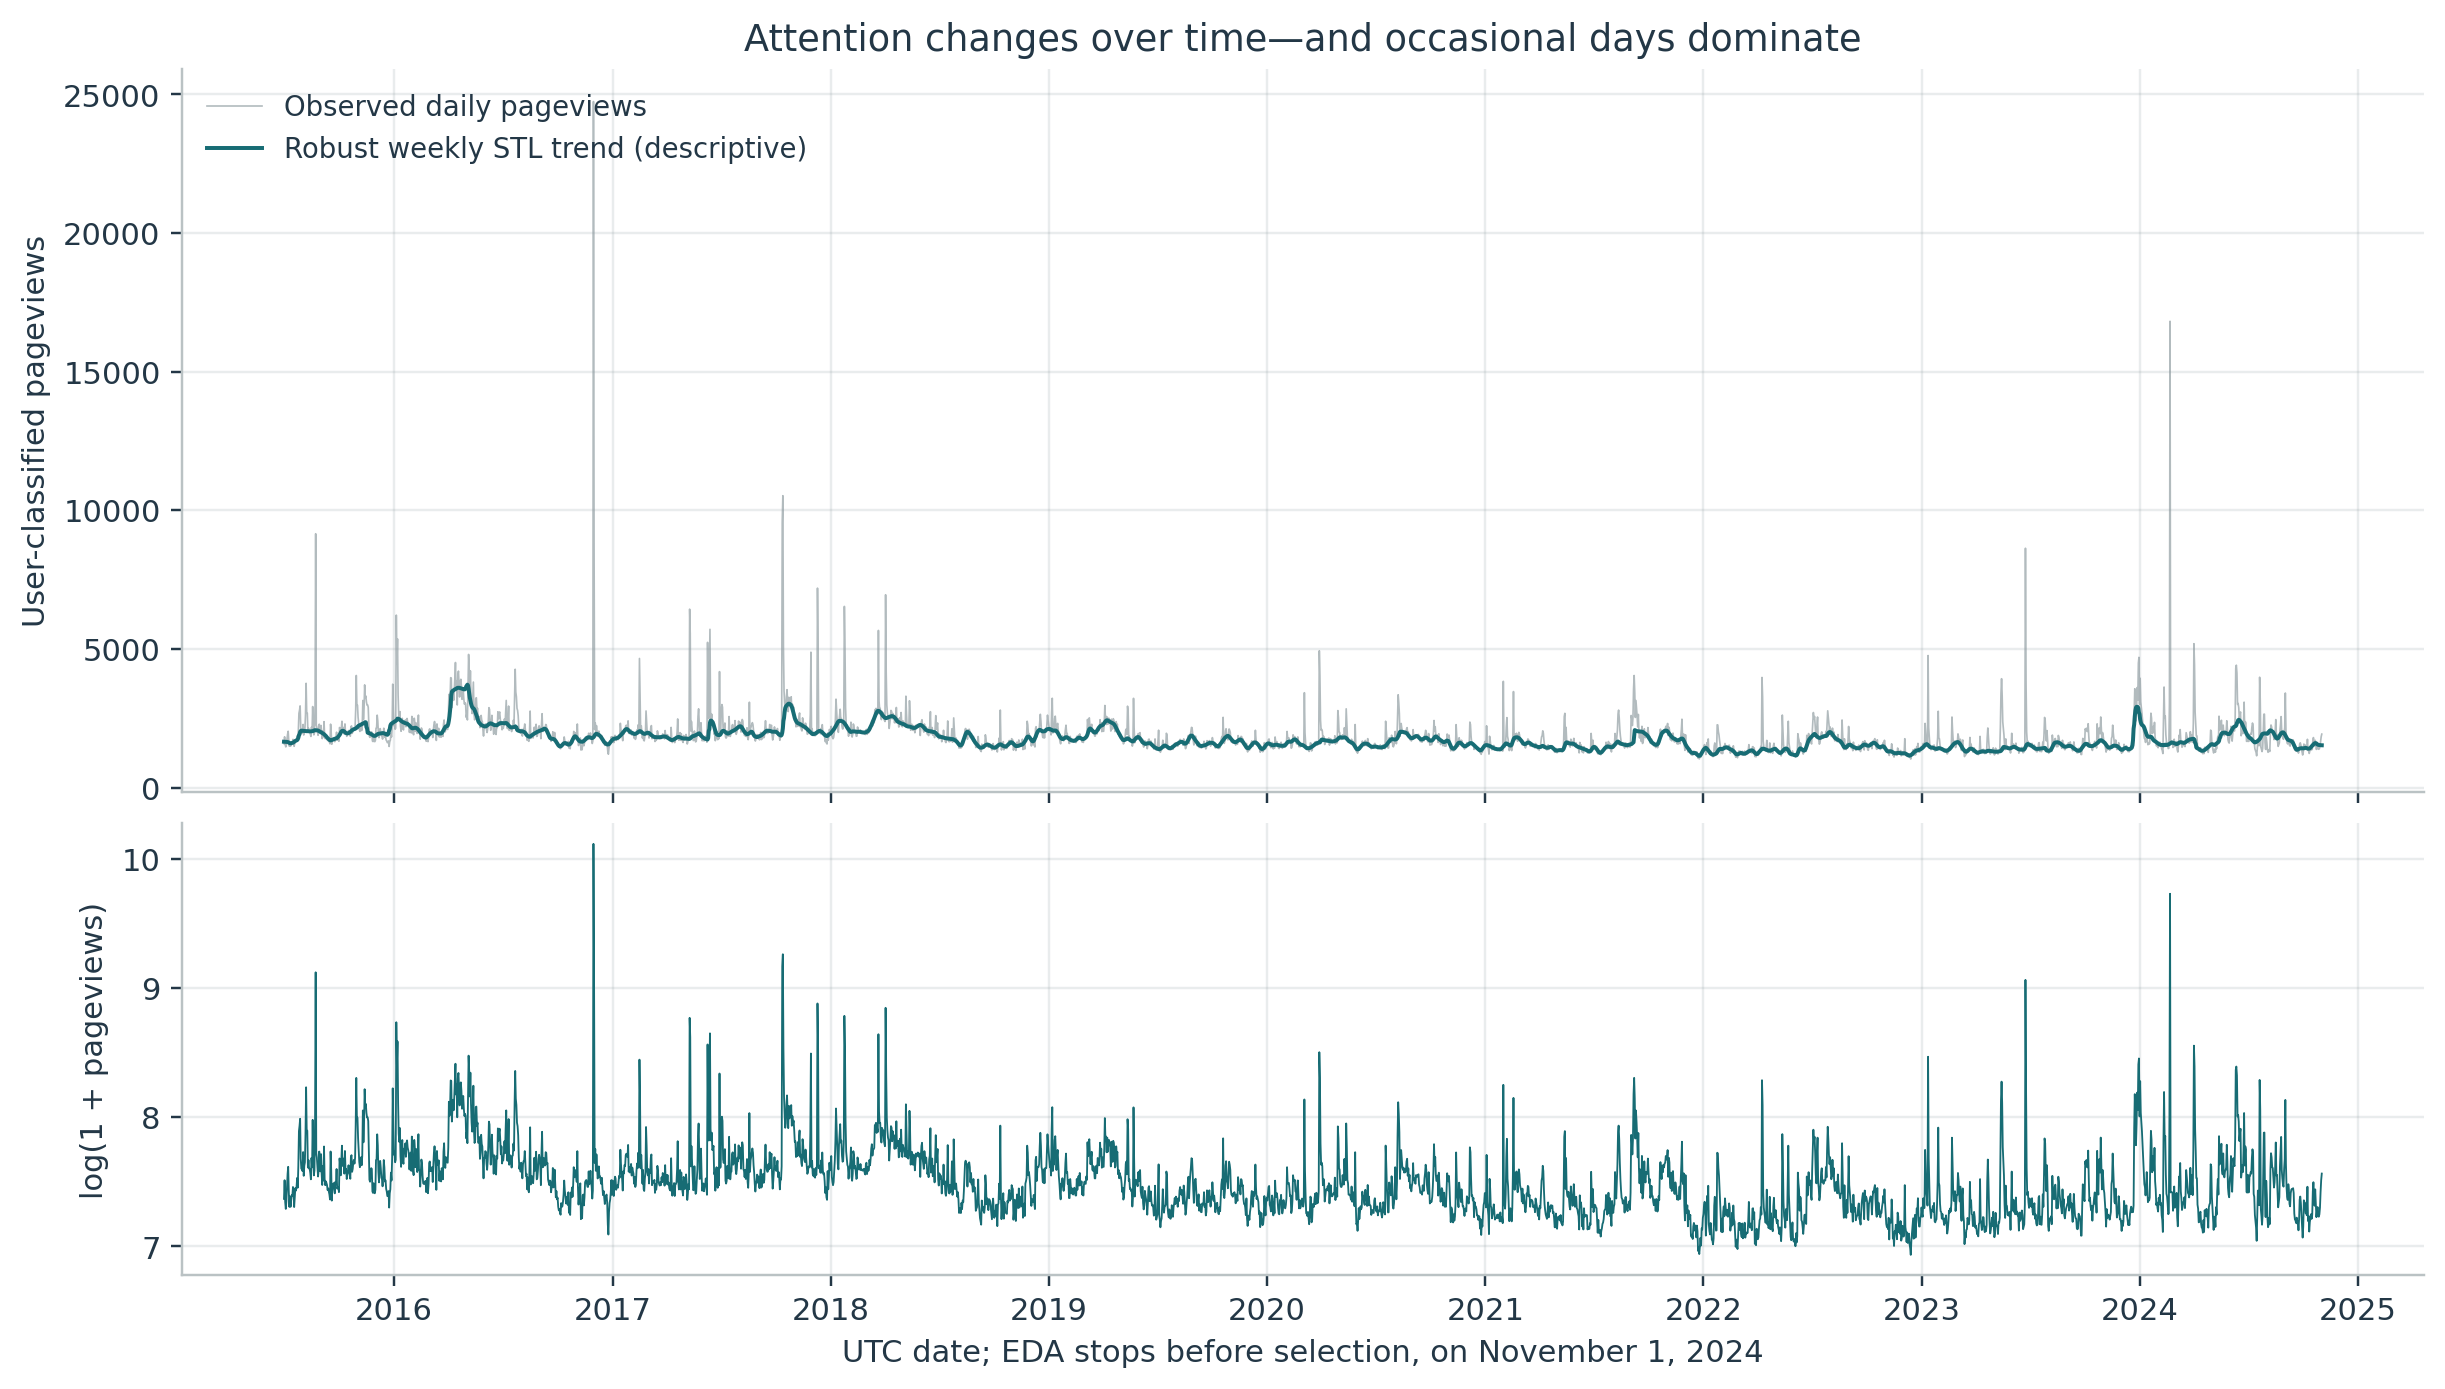

Figure 1. Pre-selection history and descriptive variability; no observations are removed.


In [3]:
display(Image(filename=str(ROOT / 'figures/development/01_attention_history.png')))
print('Figure 1. Pre-selection history and descriptive variability; no observations are removed.')

In [4]:
annual = pd.read_csv(P1 / 'annual_descriptive.csv')
display(annual.round(1))

,year,count,mean,median,std,max,complete_calendar_year
0,2015,184,2103.8,1970.5,698.5,9153.0,False
1,2016,366,2316.0,2080.5,1399.1,24744.0,True
2,2017,365,2189.1,1967.0,891.1,10526.0,True
3,2018,365,2037.1,1985.0,602.5,6952.0,True
4,2019,365,1772.1,1692.0,328.8,3220.0,True
5,2020,366,1695.8,1619.5,357.7,4930.0,True
6,2021,365,1640.3,1535.0,405.3,4041.0,True
7,2022,365,1494.5,1403.0,348.1,3969.0,True
8,2023,365,1617.0,1466.0,610.1,8630.0,True
9,2024,306,1882.1,1665.0,1034.7,16817.0,False


### What the dependence and stationarity checks contributed

The saved weekday profiles have medians of roughly **1,683 to 1,760 views**.
That modest range is quite different from the largest individual spikes.
Wednesday's mean is especially sensitive to extreme dates. The annual profile
uses only complete years 2016 to 2023, normalized by each year's median; it
suggests calendar structure without establishing a stable annual mechanism.

Figure 2 examines a different question: how dependence and variability change
across the record. The left panel shows positive raw autocorrelations over
many lags. After subtracting the same weekday one week earlier, the middle
panel has a pronounced negative lag-seven correlation. The right panel shows
that the rolling 90-day standard deviation relative to its mean is not stable.
A weekly pattern alone would not account for all of that behavior.

The tests below need to be read with their different null hypotheses in mind:

- **Raw series:** ADF rejects its unit-root null (`p ≈ 2.0 × 10⁻¹⁵`), while
  KPSS rejects its level-stationarity null. That combination does not certify
  one stable forecasting regime.
- **Weekly difference:** ADF again rejects a unit root, while KPSS does not
  reject level stationarity at conventional thresholds. This makes weekly
  differencing worth examining, without proving it necessary or optimal.

The reported KPSS values **0.01 and 0.10 are table limits**. The saved warnings
say that the raw-series p-value is below 0.01 and the differenced-series
p-value is above 0.10. These are diagnostic warnings about reporting bounds,
not failed forecasting fits.

I used these findings to motivate candidates and history-window comparisons.
Forecast MAE would decide which specified procedure to carry forward. The
negative lag-seven correlation later became relevant to the differencing
diagnosis, but it was not a conclusive diagnosis by itself.

The dependence checks gave me candidate representations to compare. Before
fixing those inputs, I also examined whether the musical history could supply
information beyond the calendar and recorded traffic.


,series,adf_statistic,adf_p,adf_lags,kpss_statistic,kpss_p_table_value,kpss_lags,warnings
0,raw,-9.201066,2.001451e-15,13,3.851298,0.01,30,The test statistic is outside of the range of p-values availa...
1,weekly_difference,-15.084562,8.360819e-28,28,0.003048,0.10,2,The test statistic is outside of the range of p-values availa...


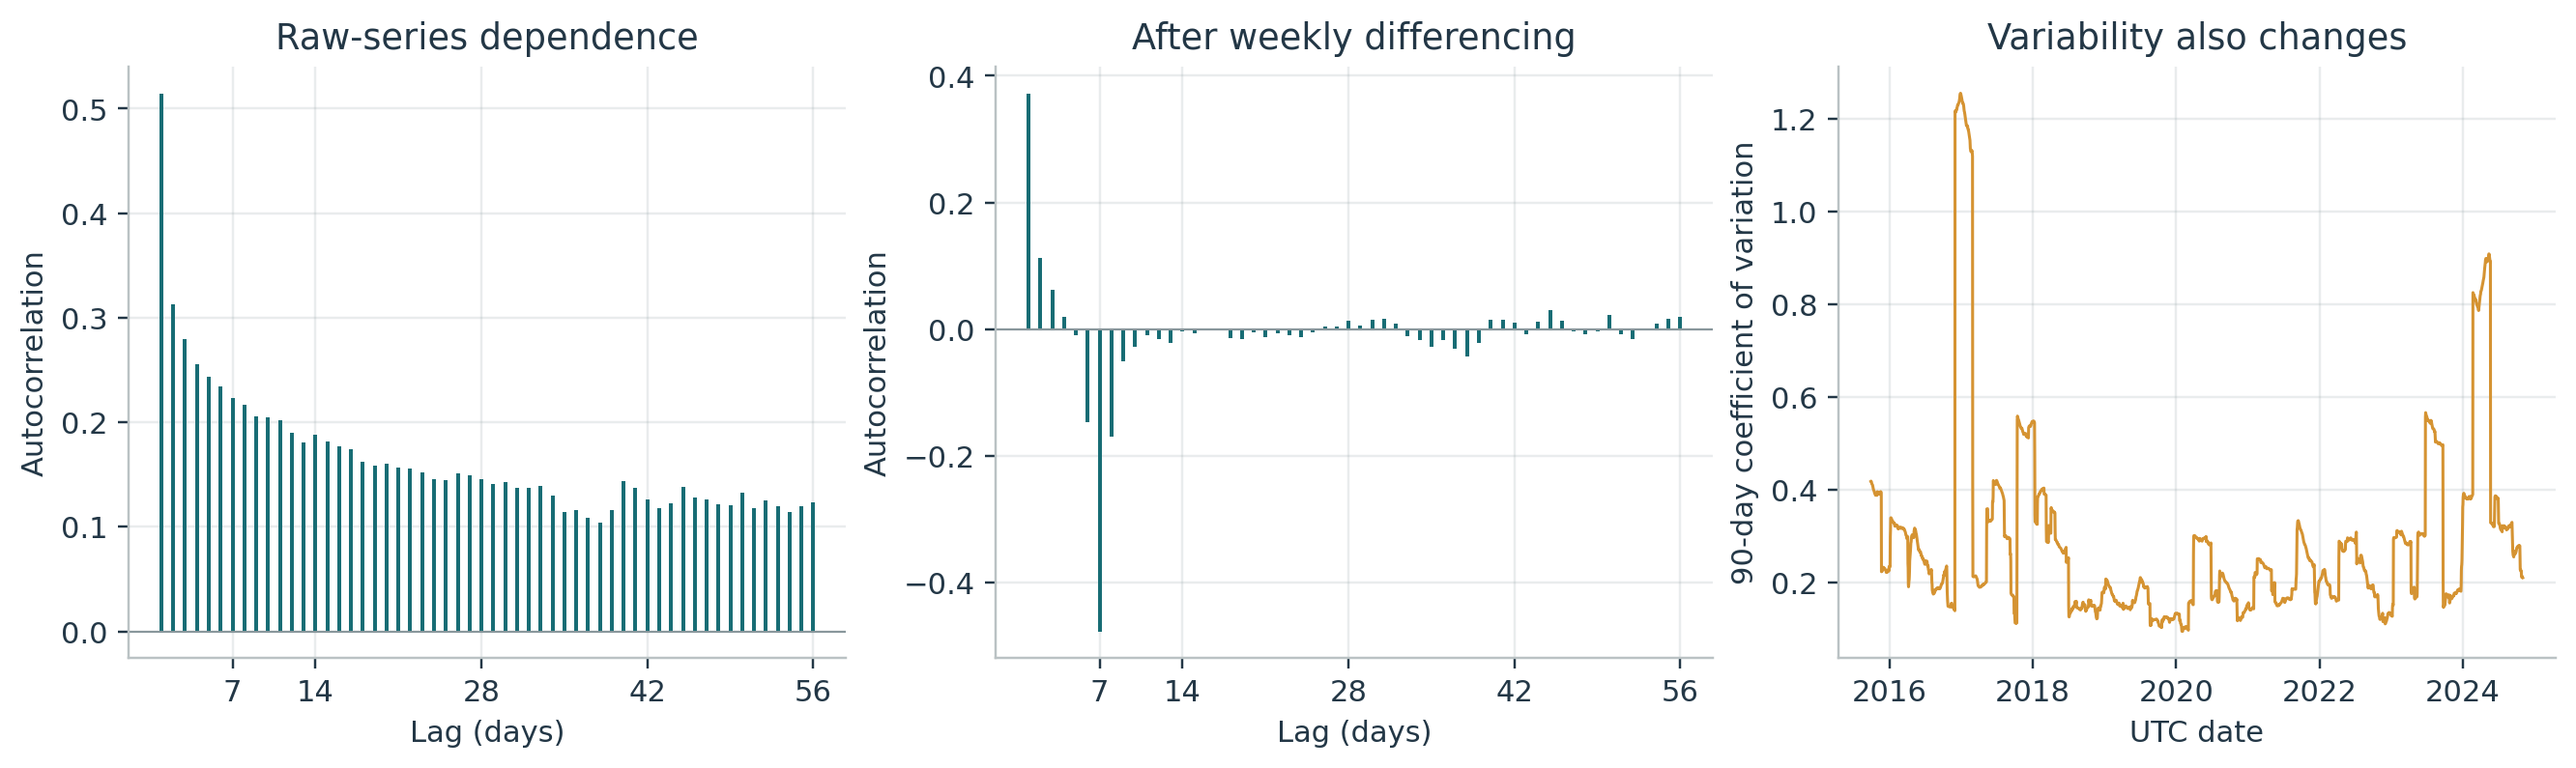

Figure 2. Dependence diagnostics within the original EDA boundary; these do not select differencing by themselves.


In [5]:
display(pd.read_csv(P1 / 'stationarity_diagnostics.csv'))
display(Image(filename=str(ROOT / 'figures/development/03_dependence_variability.png')))
print('Figure 2. Dependence diagnostics within the original EDA boundary; these do not select differencing by themselves.')

## 3. Reading the musical history alongside the traffic

As a fan, I wanted to know whether the musical history could contribute more
than context. The difficult part was establishing what a forecaster could
actually have known before each event. I group the descriptive musical cases
here for readability, while identifying those examined after model evaluation.
Their position in the notebook does not make them forecasting inputs.

The **23-entry event ledger** distinguishes verified advance announcements
(A), artist/distributor dates with uncertain advance notice (B), and unresolved
information (C). Its four A-class musical episodes predate the scored
development paths; the remaining A entry is a recurring calendar hypothesis.
Too few eligible advance-known musical episodes remained to pass the
predictive event gate. The forecasting models therefore use **no event
covariates**.

Edition distinctions matter here. *Oven Mitts* and *Live Feathers* identify live
album releases, not recording dates. *Sky Writing* includes live material as
well as its title track. *Hold Me Forever* predates the pageview coverage, and
the day conflict for *Rain Drops on Christmas* remains unresolved. The ledger
is selective, rather than a complete daily inventory of releases.

The next table gives the B-class dates inside the pre-selection history a
descriptive role. Its `following7_over_prior28` column divides the mean views
over seven days beginning on the listed date by the preceding 28-day mean.
A value above one means higher traffic in that window; below one means lower.

The three Halloween 2015 entries are part of one coordinated episode, and
other windows can overlap. These selected ratios are neither independent
replications nor estimates of release effects. They do not determine event
eligibility or enter the forecasting features.


In [6]:
context = pd.read_csv(P1 / 'event_context_descriptive.csv')
assert pd.to_datetime(context.date).max() < pd.Timestamp('2024-11-03')
display(context[['event_id', 'title', 'date', 'following7_over_prior28', 'source_url']].round(3))

,event_id,title,date,following7_over_prior28,source_url
0,E02,31 Days Til Halloween: Visitor From The Mirror,2015-10-01,1.139,https://bucketheadpikes.bandcamp.com/album/31-days-til-hallow...
1,E03,8 Days Til Halloween: Flare Up,2015-10-24,1.246,https://bucketheadpikes.bandcamp.com/album/8-days-til-hallowe...
2,E04,Happy Halloween: Silver Shamrock,2015-10-31,1.131,https://bucketheadpikes.bandcamp.com/album/happy-halloween-si...
3,E06,Adrift in Sleepwakefulness,2017-02-01,0.984,https://bucketheadpikes.bandcamp.com/album/adrift-in-sleepwak...
4,E07,Healing Inside Outside Every Side — digital edition,2020-04-04,0.948,https://bucketheadpikes.bandcamp.com/album/healing-inside-out...
5,E08,Galaxies,2021-05-30,0.938,https://bucketheadpikes.bandcamp.com/album/galaxies
6,E09,Oven Mitts — live album release,2021-07-09,0.877,https://bucketheadpikes.bandcamp.com/album/oven-mitts
7,E10,Furnace Follies,2022-05-11,1.201,https://bucketheadpikes.bandcamp.com/album/furnace-follies
8,E11,Live Feathers — live album release,2022-06-21,1.215,https://bucketheadpikes.bandcamp.com/album/live-feathers
9,E12,Dreams Remembered,2022-07-05,1.376,https://bucketheadpikes.bandcamp.com/album/dreams-remembered


### What the release-adjacent ratios show

The two windows I found most instructive point in opposite directions.
*Dreams Remembered*, dated **July 5, 2022** in the examined digital edition,
has a ratio of **1.376**: its following-week mean is about **38% higher** than
the preceding mean. *Sea Above The Sky*, dated **January 27, 2024**, has a ratio
of **0.671**, about **33% lower**.

I could not turn those contrasts into a general rule that releases raise
Wikipedia traffic. Visiting an encyclopedia page is different from listening
to an album, and background traffic, overlapping activity, edition timing and
publicity remain uncontrolled. The table describes the chosen windows; it
does not identify audience responses caused by the music.

A release or edition date identifies an artifact. A recording date identifies
its creation. A public announcement date can establish advance information.
The ledger's **November 5, 2026 review date** and the later source check date
the verification work, not what was publicly known before an earlier forecast.
That distinction kept historical context separate from predictive inputs.


### Historical case H1: the October 2017 interview coverage

An interview offered another way to read the history. The
[podcast publisher](https://www.thetoolsbook.com/blog/a-conversation-with-buckethead)
identifies Barry Michels' *Coming Alive* conversation with Buckethead, including
discussion of heart problems. I examined this case after model evaluation,
during Phase 3. It is a retrospective illustration, with the health reporting
understood in its historical context.

The source dates refer to different things:

| Date | What the evidence dates |
|:---|:---|
| October 10, 2017 | [Listen Notes](https://www.listennotes.com/podcasts/coming-alive/a-conversation-with-buckethead-9jrG3mSnNuR/) lists the episode on this date. The original RSS timestamp and recording date were not recovered. |
| October 12, 2017 | [Loudwire](https://loudwire.com/buckethead-life-threatening-heart-condition/) publishes coverage of the conversation; Alternative Nation also carries this date. The interview was public by then. |
| October 13, 2017 | [Louder](https://www.loudersound.com/news/buckethead-diagnosed-with-heart-condition) publishes further coverage. |
| August 25, 2022 | The current publisher page's `datePublished` metadata. This later page date is not the original interview date and is not marked as an event in the plot. |

I used **October 12** as the documented coverage anchor. The reference window
is **September 14 to October 11**, the preceding 28 UTC days; the following
week is **October 12 to 18**, inclusive. These match the saved historical report.
The table below divides each daily count by that same reference mean.

In historical figure H1, the gray band is the reference period's observed
minimum and maximum, **not a prediction interval**. Publication dates have
calendar-day precision; intraday UTC ordering remains unresolved.


,pageviews,relative_to_prior28_mean
date,,
2017-10-09,1851,0.925
2017-10-10,1838,0.919
2017-10-11,2040,1.020
2017-10-12,9580,4.788
2017-10-13,10526,5.261
2017-10-14,5071,2.534


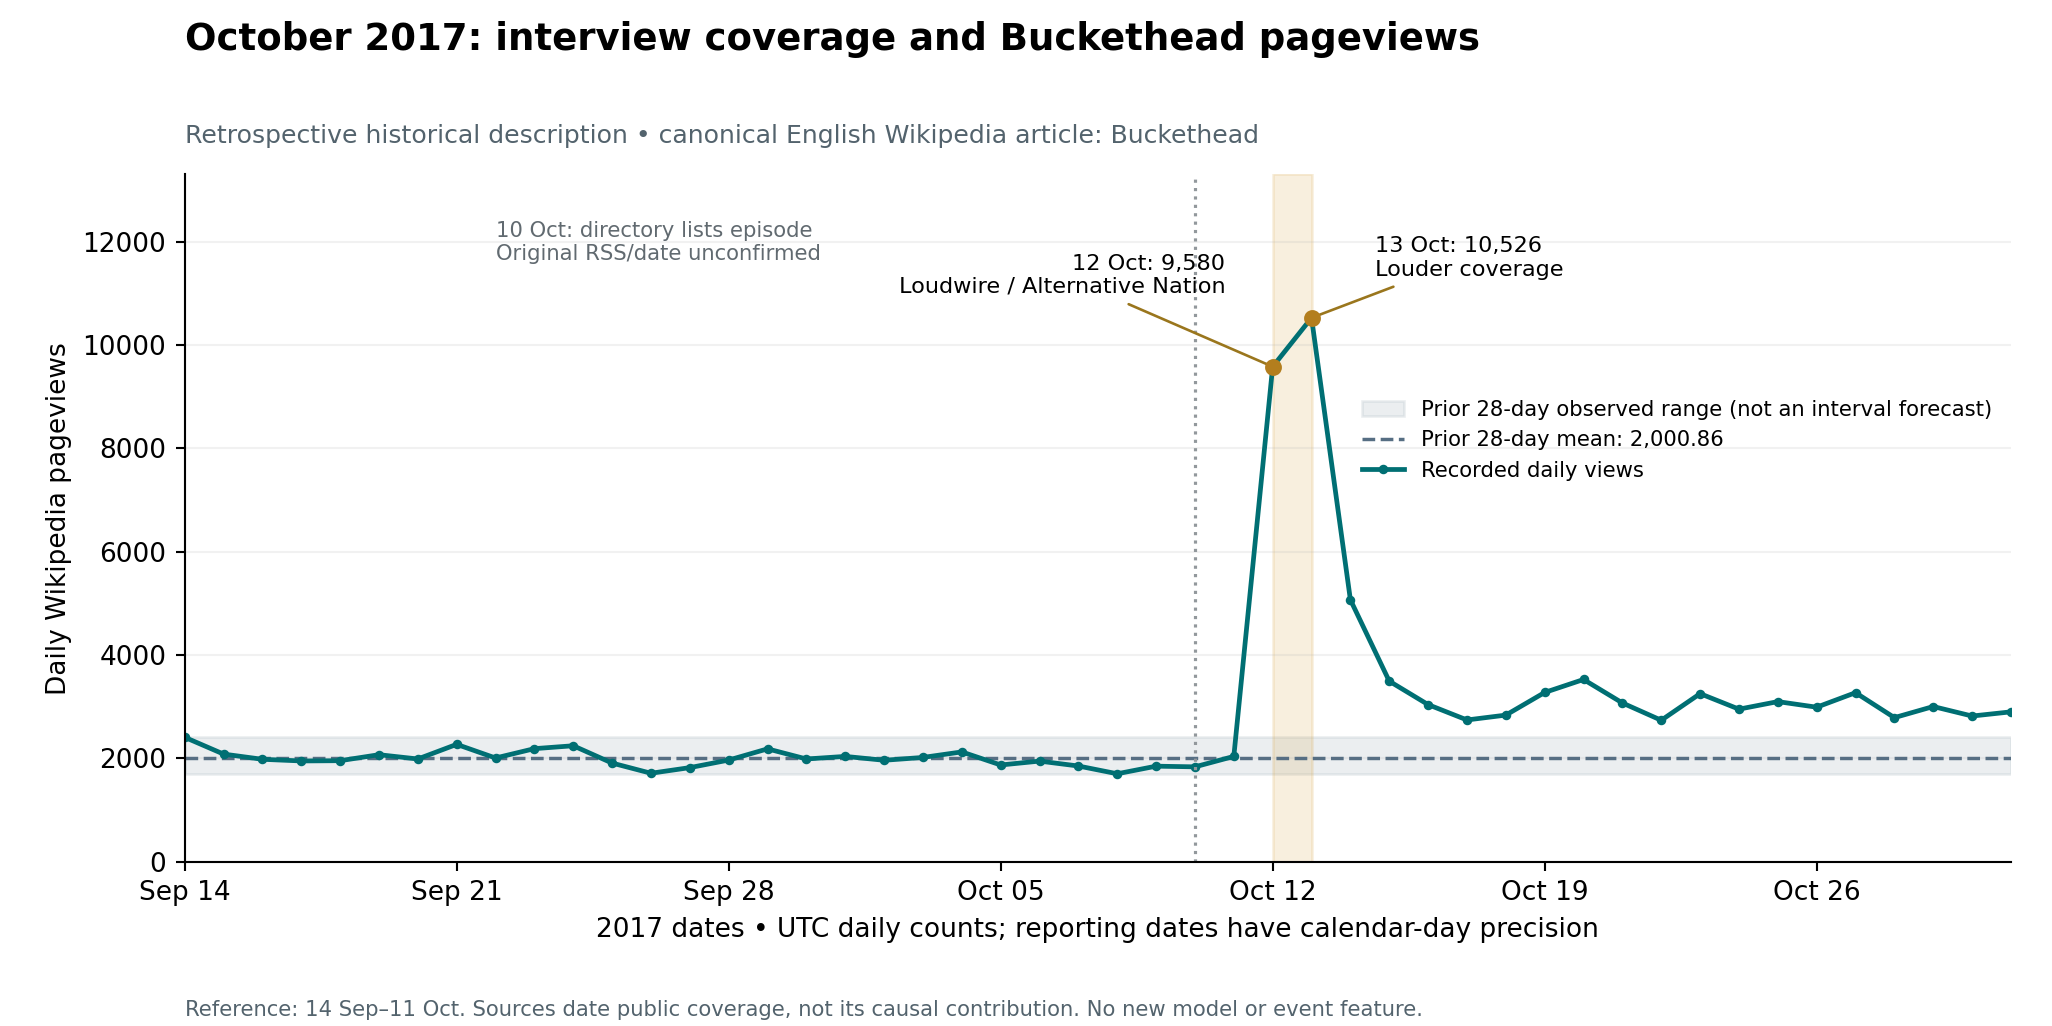

Historical figure H1. One retrospective case; source chronology does not establish causal contribution.


In [7]:
# Added retrospective description only: no fit, event feature or research write.
from interview_case import describe as describe_interview
interview_daily, interview_facts = describe_interview(full_y)
recorded_interview = json.loads((ROOT / 'results/historical_context/interview_facts.json').read_text())
for key, value in interview_facts.items():
    if isinstance(value, (int, float)):
        np.testing.assert_allclose(value, recorded_interview[key], rtol=1e-13)
display(interview_daily.loc['2017-10-09':'2017-10-14'].round(3))
display(Image(filename=str(ROOT / 'figures/historical_context/interview_case.png')))
print('Historical figure H1. One retrospective case; source chronology does not establish causal contribution.')

### Reading the jump without attributing a cause

The reference mean was **2,000.86 views/day**, with an observed range of
**1,704 to 2,410**. The displayed counts for October 10 and 11 remain within
that range. They then rise to **9,580 on October 12** and **10,526 on October
13**, approximately **4.79** and **5.26 times** the reference mean. The full
following-week mean is **5,328.43**, or **2.663 times** the reference.

The directory's October 10 date falls inside the last two days of the main
reference. The saved chronology check moves that reference to **September 12
to October 9**. Its mean becomes **2,004.86**, and the same following-week ratio
is **2.658**. The contrast remains substantial under that earlier window.

This gave me a useful historical anchor for the increase. Identifying the
interview's contribution would require evidence such as referrals, intraday
ordering and comparison articles. These selected windows establish temporal
association, without identifying a causal effect or a forecasting feature
known in advance.

The historical cases clarify why timing matters. I next make that boundary
explicit for every observation, feature and target in a 28-day forecast.


## 4. One issue, one information set, twenty-eight targets

At midnight UTC on issue date `O`, I use counts through **`O − 2`**. The day
`O − 1` is unobserved. Statistical models predict 29 successive days, discard
the first prediction, and score the 28 targets from `O` through `O + 27`.
Weekly naive repeats the latest available observation for each weekday.
None of these procedures updates a path using actual counts from inside it.

The saved timing example below makes that bridge concrete. For the
**November 3, 2024** issue, the latest available count is **November 1**.
The bridge begins on **November 2**, while the scored targets run from
**November 3 to November 30**. Predicting the unobserved intervening day is
necessary even though its prediction is not scored.

### Constructing the feature rows

LightGBM uses one direct, horizon-conditioned model: one fitted learner
predicts rows for all 28 steps. The
[feature builder](src/research/development/forecasting.py) supplies **17
columns**: seven cutoff-relative counts, four rolling summaries, horizon,
target weekday, and four annual Fourier terms.

All observed-count inputs are anchored at the issue's cutoff. Calendar inputs
and horizon vary across target dates. This keeps later rows feasible without
borrowing actual values from earlier steps in the forecast window.

The following is the actual feature function, retained as an explanatory
Markdown excerpt. `annual_fourier` is defined in the same source file.

```python
def feature_path(history, issue):
    """Only origin-relative target lags; no target-relative observed lags."""
    issue = pd.Timestamp(issue)
    cutoff = issue - pd.Timedelta(days=2)
    past = history.loc[:cutoff]
    if len(past) < 56 or past.index[-1] != cutoff:
        raise ValueError("Feature lookback unavailable.")
    targets = pd.date_range(issue, periods=28, freq="D")
    values = {f"count_c_minus_{k}": float(past.loc[cutoff-pd.Timedelta(days=k)]) for k in (0,1,6,7,13,27,55)}
    for length in (7,28):
        values[f"mean_{length}"] = float(past.iloc[-length:].mean())
        values[f"std_{length}"] = float(past.iloc[-length:].std(ddof=0))
    x = pd.DataFrame({name: np.repeat(value,28) for name,value in values.items()}, index=targets)
    x["horizon"] = np.arange(1,29)
    x["target_weekday"] = targets.dayofweek.to_numpy()
    return x.join(annual_fourier(targets))
```

Historical training issues use the same feature construction. Their complete
28-day labels must be available by the current cutoff, so the last eligible
training issue is `origin.cutoff - pd.Timedelta(days=27)`. Feature availability
and label maturity are separate checks.

Today's knowledge of a Pike release or interview cannot bypass this boundary.
The October 2017 case dates observed coverage, not an advance-known schedule,
and predates the scored development paths. It does not supply the missing set
of eligible musical events.


In [8]:
O = pd.Timestamp('2024-11-03')
C = O - pd.Timedelta(days=2)
targets = pd.date_range(O, periods=28)
bridge = pd.date_range(C + pd.Timedelta(days=1), targets[-1])
assert len(bridge) == 29 and bridge[1:].equals(targets)
display(pd.Series({'issue': O, 'latest_available': C,
    'prediction_bridge_start': bridge[0], 'target_start': targets[0],
    'target_end': targets[-1], 'bridge_predictions': len(bridge)}))
# This is an information-boundary illustration, not a new forecast.
np.testing.assert_allclose(saved.weekday_forecast(full_y, '2025-11-02'),
    original_final.loc[(original_final.issue == '2025-11-02') &
                       (original_final.family == 'weekday_mean'), 'prediction'])

issue                      2024-11-03 00:00:00
latest_available           2024-11-01 00:00:00
prediction_bridge_start    2024-11-02 00:00:00
target_start               2024-11-03 00:00:00
target_end                 2024-11-30 00:00:00
bridge_predictions                          29
dtype: object

### Reading the scores and the tuned configurations

I select procedures by **MAE**, the mean absolute error in views/day. With
`e = prediction − actual`, MAE is `mean(|e|)` and pooled RMSE is
`sqrt(mean(e²))`. RMSE gives larger misses more influence. **MASE** averages
`|e| / q[origin]`, where the scale is calculated only from available training
observations.

Each origin uses one common scale: the mean absolute seven-day difference
within its last three calendar years, ending at `O − 2`. The denominator does
not change with the candidate's training window. MASE below one means error
below that historical scale; it does not automatically establish an advantage
over the evaluated 28-day weekly-naive forecast.

The two seasonal references give the fitted models a concrete test. Weekly
naive repeats the latest available count for each weekday. The weekday mean
averages the available matching weekdays in a short trailing window: an
eight-week Tuesday forecast averages eight earlier Tuesdays. Both respect
the same `O − 2` cutoff throughout the full path.

I compared expanding and three-year histories for SARIMAX, Prophet and
LightGBM. The baselines keep their short-history rules. The **19 tuning
configurations across 12 paths** produce **228 procedure-origin evaluations**:
**192 fitted-model attempts plus 36 baseline paths**. The eight carried
procedures then produce **96 selection evaluations**, comprising **72
fitted-model paths plus 24 baseline paths**.

The table below shows what tuning selected, before the later selection scores
are examined:

- **SARIMAX:** nonseasonal order `(1,0,1)` for both windows, with seasonal order
  `(0,1,1)[7]` and annual Fourier terms fixed by the original recipe.
- **Prophet:** `changepoint_prior_scale=0.01` for both windows.
- **LightGBM:** seven leaves with expanding history and 15 with three years.
- **Weekday mean:** eight weeks, selected from four- and eight-week candidates.
  Weekly naive has no grid choice.

These are small, unequal searches: SARIMAX offers four orders per window,
Prophet two changepoint priors, and LightGBM two leaf counts. The results compare
these specific recipes, rather than equally optimized model families. Full
settings and timing clarifications remain in the
[Phase 1 implementation record](provenance/protocols/development/PROTOCOL_IMPLEMENTATION.md).


In [9]:
registry = json.loads((P1 / 'candidate_registry.json').read_text())
assert len(registry['specifications']) == 19
display(pd.DataFrame(json.loads((P1 / 'tuned_configurations.json').read_text())))

,family,window,params
0,lightgbm,expanding,{'num_leaves': 7}
1,lightgbm,three_years,{'num_leaves': 15}
2,prophet,expanding,{'changepoint_prior_scale': 0.01}
3,prophet,three_years,{'changepoint_prior_scale': 0.01}
4,sarimax,expanding,"{'order': [1, 0, 1]}"
5,sarimax,three_years,"{'order': [1, 0, 1]}"
6,weekday_mean,fixed,{'weeks': 8}
7,weekly_naive,fixed,{}


## 5. Development comparison and the selected candidate

With tuning complete, I used the next **12 scored selection paths** to choose
the procedure and history policy. Hyperparameters stayed fixed; models were
fitted again using the observations available at each origin. Because paths
have equal length, mean path MAE equals the pooled daily MAE here. Pooled RMSE
uses all squared daily errors, rather than averaging path RMSE values.

The next output ranks all eight procedures. Its `failures` and `eligible`
columns matter alongside the scores: a numerical failure would use the logged
weekly-naive fallback and make that selection procedure ineligible. AIC was
retained as a diagnostic; forecast MAE selected the SARIMAX order.

### What the fitted families contribute

The three fitted families represent the problem differently. Prophet models
trend and calendar seasonality; LightGBM learns nonlinear combinations of the
available history and calendar features; SARIMAX combines calendar regressors
with temporal dependence in the remaining process. Their common comparison
comes from the task and forecast occasions, while the fitted representations
and search budgets differ.

I explain the selected SARIMAX more closely because its fitted structure later
becomes part of the failure investigation.

### What the selected SARIMAX represents

Annual sine and cosine regressors describe smooth calendar variation. The
remaining process `u[t]` follows

`(1 − φB)(1 − B⁷)u[t] = (1 + θB)(1 + ΘB⁷)ε[t]`,

with `y[t] = Fourier[t]β + u[t]` and `B` shifting a series back one day.
After taking the weekly difference `w[t] = u[t] − u[t−7]`, AR(1) links this
remainder to its previous value. MA(1) and seasonal MA(1) describe dependence
on innovations one and seven days earlier; multiplying the factors also
produces a lag-eight innovation term. These moving-average terms concern
unpredictable shocks, not averages of observed counts in the weekday baseline.

The order **`(1,0,1)(0,1,1)[7]`** has one weekly difference, no ordinary
difference and no seasonal AR term. Forecast validation selected it within
the original grid. The stationarity tests alone did not establish its value.

### The selected SARIMAX in code

The [preserved implementation](src/research/development/forecasting.py) resolves
to the following settings for the selected three-year procedure.
`training_history` and `annual_fourier` are helpers from that file. This
Markdown excerpt omits convergence checks and audit logging, which remain in
the executable runner; it is not a new fitting cell.

```python
train = training_history(origin, "three_years")
model = SARIMAX(
    train, exog=annual_fourier(train.index, k=2),
    order=(1, 0, 1), seasonal_order=(0, 1, 1, 7),
    enforce_stationarity=True, enforce_invertibility=True, trend=None,
)
result = model.fit(method="lbfgs", maxiter=200, disp=False)
bridge_prediction = result.get_forecast(
    steps=29, exog=annual_fourier(origin.bridge, k=2)
).predicted_mean
forecast = np.maximum(bridge_prediction.iloc[1:].to_numpy(), 0)
```

The model uses raw counts, two annual Fourier harmonics (four regressors), no
separate trend and L-BFGS with at most 200 iterations. The bridge supplies the
unobserved intervening day before retaining the 28 targets. Negative point
predictions are clipped at zero.

**Failure handling across versions.** Every recorded real-data run had zero
fallbacks. The archived runners caught broad `ValueError` and `RuntimeError`
exceptions as well as numerical failures. The current adapter rejects those
unexpected-error fallbacks before scoring or caching, while preserving logged
`ModelFailure` and `LinAlgError` fallbacks. The
[documented policy](docs/reproducibility.md#numerical-fallback-and-unexpected-errors)
changes current error handling without changing the archived fits or results.


,family,window,params,mae,rmse,mase,failures,eligible
0,sarimax,three_years,"{'order': [1, 0, 1]}",303.985,455.074,0.754,0,True
1,lightgbm,expanding,{'num_leaves': 7},310.332,478.121,0.766,0,True
2,lightgbm,three_years,{'num_leaves': 15},317.913,498.729,0.784,0,True
3,weekday_mean,fixed,{'weeks': 8},326.659,489.402,0.804,0,True
4,prophet,expanding,{'changepoint_prior_scale': 0.01},371.880,502.704,0.924,0,True
5,prophet,three_years,{'changepoint_prior_scale': 0.01},373.607,517.924,0.929,0,True
6,sarimax,expanding,"{'order': [1, 0, 1]}",394.069,518.212,0.979,0,True
7,weekly_naive,fixed,{},467.307,660.015,1.150,0,True


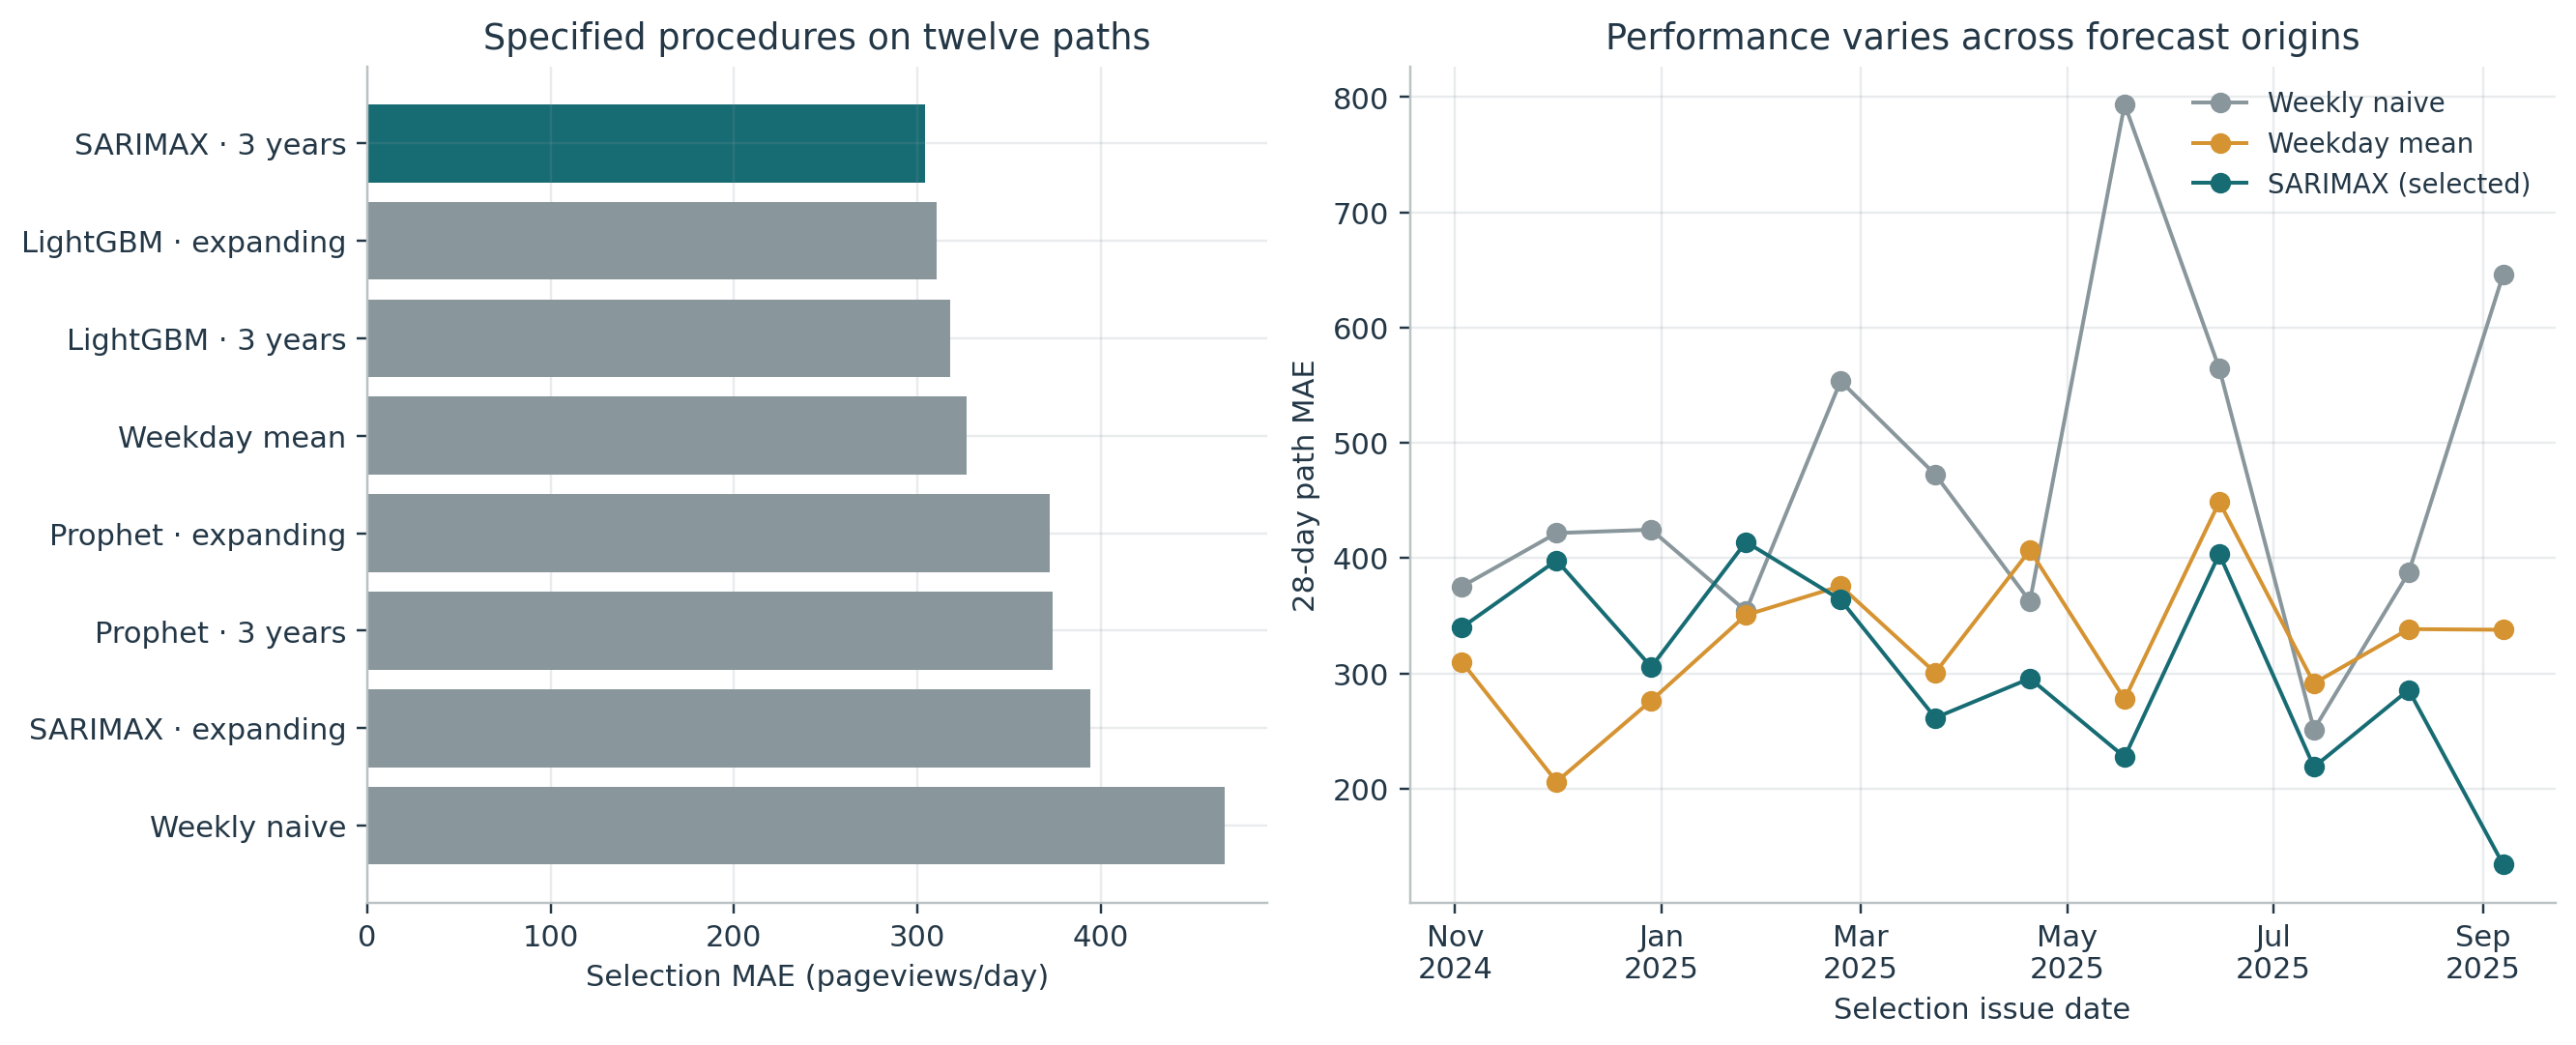

Figure 3. Original chronological selection comparison; the small unequal search grids are disclosed.


In [10]:
selection = pd.read_csv(P1 / 'selection_summary.csv')
display(selection[['family', 'window', 'params', 'mae', 'rmse', 'mase', 'failures', 'eligible']].round(3))
display(Image(filename=str(ROOT / 'figures/development/05_development_comparison.png')))
print('Figure 3. Original chronological selection comparison; the small unequal search grids are disclosed.')

### What the selection table established

The three-year SARIMAX leads with **MAE 303.98**, **RMSE 455.07**, and
**MASE 0.754**. Its MAE is **6.94% below** the eight-week weekday mean and
**34.95% below** weekly naive. It beats those baselines on eight and eleven
of the 12 paths, respectively.

Expanding-history LightGBM is much closer: **MAE 310.33**, a gap of only
**6.35 views/day**, and each method wins six paired paths. The MAE rule still
selects SARIMAX. I read that as a selection from the observed paths, without
claiming statistical superiority or guaranteed future performance. All eight
procedures are eligible, and all **324 tuning-plus-selection evaluations**
completed without fallback or recorded Python warnings. Unfavorable tuning
configurations remain in the saved record.

### History length and the numerical preflight

The table below defines its last column as **expanding MAE minus three-year
MAE**. SARIMAX's positive difference of **90.084** favors the shorter history.
The negative differences for LightGBM (**−7.581**) and Prophet (**−1.727**)
favor expanding history. LightGBM also selected different leaf counts in the
two windows, so its contrast includes that tuning choice. These results did
not support one common history-length rule for every family.

Before final evaluation, I also checked a concern hidden by the favorable
SARIMAX score. Across its 12 selected-order fits, the seasonal MA coefficient
ranges from **−0.999984 to −0.999837**. The minimum MA-root moduli range from
**1.000002 to 1.000023**, just outside the invertibility boundary. The maximum
absolute optimizer gradients range from approximately **7.4 × 10⁻⁷ to
3.3 × 10⁻⁵**.

The saved preflight reports **12 fits checked, 23 targeted tests passed, and
no protocol corrections**. AR and MA roots met the numerical checks, and
saved-parameter filtering reproduced forecasts. Poorly conditioned covariance
matrices still limit coefficient interpretation; their condition numbers also
depend on units.

The preflight retained the selected recipe and fallback rule without retries
or new thresholds. Repeatable computation did not establish identification,
global optimality or suitability for the next period. I return to the
near-boundary estimate during failure diagnosis. Before that evaluation, I
also needed to fix how uncertainty would be reported around each prediction.


In [11]:
display(pd.read_csv(P1 / 'training_window_effects.csv').round(3))
preflight = json.loads((P2 / 'preflight.json').read_text())
numerics = pd.read_csv(P2 / 'development_numerical_audit.csv')
display(pd.Series({key: preflight[key] for key in ['status', 'development_selection_fits_checked',
    'minimum_ma_root_modulus', 'maximum_ma_root_modulus', 'targeted_tests_passed', 'protocol_corrections']}))
display(numerics[['ma.S.L7', 'minimum_ma_root_modulus',
    'maximum_absolute_optimizer_gradient']].agg(['min', 'max']))

,family,expanding,three_years,expanding_minus_three_years
0,lightgbm,310.332,317.913,-7.581
1,prophet,371.880,373.607,-1.727
2,sarimax,394.069,303.985,90.084


status                                  passed
development_selection_fits_checked          12
minimum_ma_root_modulus               1.000002
maximum_ma_root_modulus               1.000023
targeted_tests_passed                       23
protocol_corrections                        []
dtype: object

,ma.S.L7,minimum_ma_root_modulus,maximum_absolute_optimizer_gradient
min,-0.999984,1.000002,7.415402e-07
max,-0.999837,1.000023,3.319904e-05


## 6. One modest uncertainty procedure

I wanted the selected procedure to report uncertainty as well as point
predictions. The original rule uses its **336 selection-era absolute errors**
to construct a fixed nominal **80% pointwise interval**.

The rank is `ceil((336 + 1) × 0.8) = 270`. As the saved output below shows,
the 270th smallest error gives a half-width of **408.286529 views**. For a
nonnegative point prediction `p`, the bounds are `[max(0, p − q), p + q]`.
Width is measured after clipping, and `q` stays fixed throughout final
evaluation.

The displayed calibration dates are **November 3, 2024, to October 4, 2025**.
The `selection_reuse_disclosed=True` flag records an important limitation:
these errors also helped select the model and window. Calibration is therefore
not an independent assessment of the complete selected procedure.

Dependence between errors, selection reuse and changing conditions leave no
asserted finite-sample distribution-free guarantee here. I assess the observed
coverage on the next period using the unchanged rule, rather than treating
the nominal percentage as an established property of the forecasts.


In [12]:
calibration = pd.read_csv(P1 / 'calibration_errors.csv')
interval = config['interval']
assert len(calibration) == 336 and interval['rank'] == 270
assert np.isclose(np.sort(calibration.absolute_error)[269], interval['half_width'])
display(pd.Series(interval, name='Frozen development-only interval calibration'))

nominal_coverage                                                     0.8
method                       fixed pooled absolute-error order statistic
n                                                                    336
rank                                                                 270
half_width                                                    408.286529
calibration_first                                             2024-11-03
calibration_last                                              2025-10-04
selection_reuse_disclosed                                           True
Name: Frozen development-only interval calibration, dtype: object

## 7. Testing the development winner on the final year

I carried the selected SARIMAX, weekly naive and the eight-week weekday mean
into **13 nonoverlapping 28-day paths**, covering **364 days from November 2,
2025, to October 31, 2026**. Each issue uses observations through `O − 2`.
Earlier final-period counts can enter subsequent fits once available, while
the model configuration and interval half-width stay fixed.

The table below shows a clear reversal:

- **Weekday mean:** MAE **238.733**, RMSE **308.367**, MASE **0.570**.
- **Weekly naive:** MAE **251.852**, RMSE **359.826**, MASE **0.602**.
- **Selected SARIMAX:** MAE **437.776**, RMSE **489.017**, MASE **1.050**.

SARIMAX's MAE is **83.37% higher** than the weekday mean and **73.82% higher**
than weekly naive. It wins only **two of 13 paths** against the weekday mean
and **three of 13** against weekly naive. Its development advantage did not
carry into this year.

The 13 paths have different targets but share training history and belong to
one article and one year. I treat these as dependent observations of the
specified procedures, rather than 13 independent replications.


In [13]:
final_summary = pd.read_csv(P2 / 'summary.csv')
display(final_summary.loc[final_summary.population == 'primary',
    ['family', 'paths', 'days', 'mae', 'rmse', 'mase']].round(3))
paired = pd.read_csv(P2 / 'paired_differences.csv')
print('All 13 path comparisons remain in results/original_evaluation/origin_metrics.csv and paired_differences.csv.')

,family,paths,days,mae,rmse,mase
0,sarimax,13,364,437.776,489.017,1.050
1,weekday_mean,13,364,238.733,308.367,0.570
2,weekly_naive,13,364,251.852,359.826,0.602


All 13 path comparisons remain in results/original_evaluation/origin_metrics.csv and paired_differences.csv.


### The forecasts were systematically too high

The all-path figure below helps explain why the aggregate ranking changed.
Actual counts average **1,267.4 views/day**, while the selected forecasts
average **1,629.3**. Mean forecast minus actual is therefore **+361.9
views/day**. The weekday baseline follows the lower realized level more
closely, although it also overpredicts on average.

All **13 SARIMAX fits converged**, using 20 to 37 optimizer iterations, with
no fallback or recorded Python warnings. Seasonal MA coefficients remain
near −1, approximately **−0.999986 to −0.999544**. The poor accuracy belongs
to completed forecasts; convergence did not make their levels appropriate.

Figure 4 retains all 13 paths and the unchanged interval radius. It lets me
read the level mismatch alongside individual high-traffic dates, before
examining interval coverage and the broader distribution of errors.


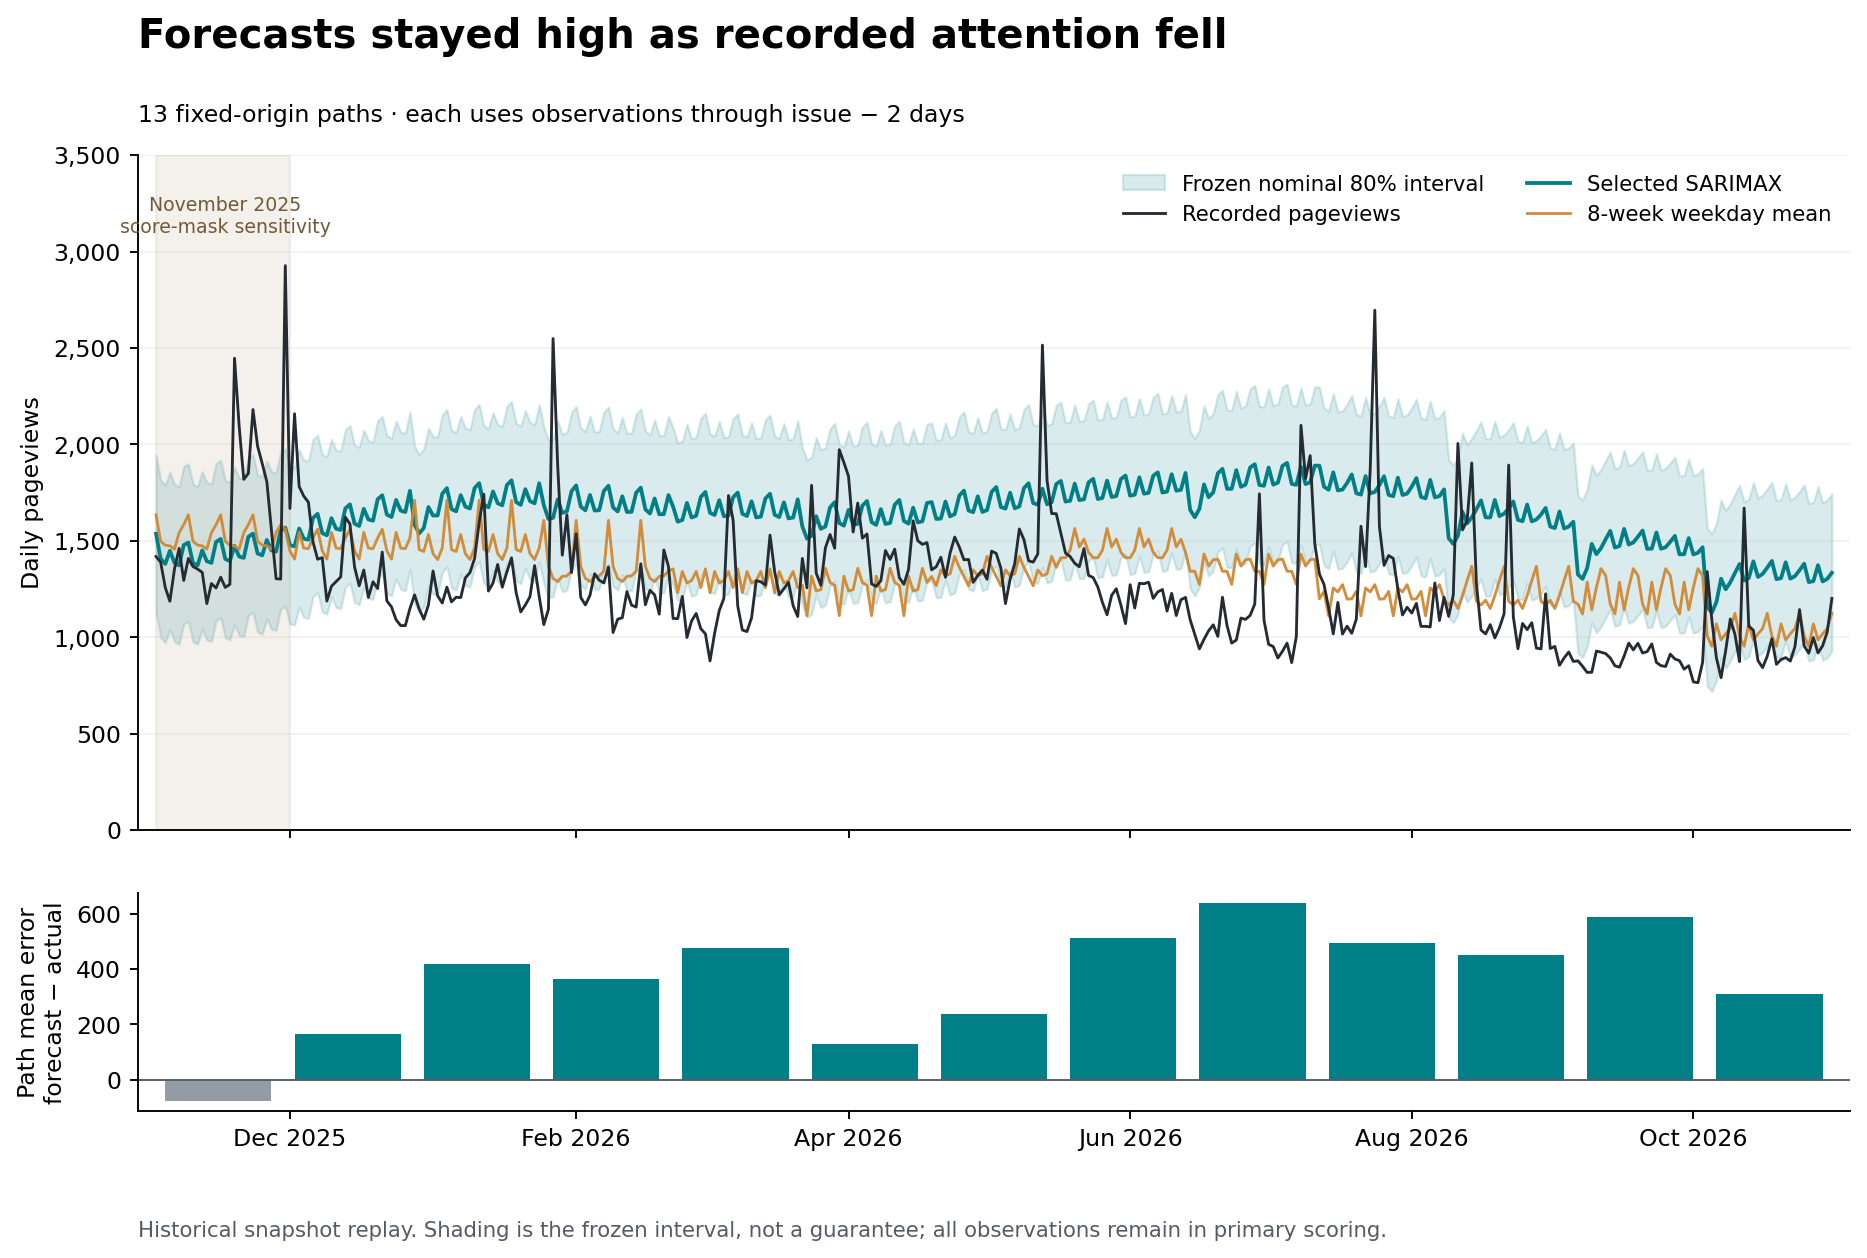

Figure 4. All 13 original final paths; settings and the interval radius remain fixed.


In [14]:
display(Image(filename=str(ROOT / 'figures/original_evaluation/06_final_forecasts.png')))
print('Figure 4. All 13 original final paths; settings and the interval radius remain fixed.')

### The interval missed mainly below its lower bound

The primary row in the next output reports **44.78% coverage** for a nominal
80% interval, with mean width **816.57 views**. Of **201 missed daily outcomes**,
**190 lie below the lower bound** and only **11 above the upper bound**. That
directional imbalance is consistent with the point forecasts being too high.
Coverage varies from **0% to 100%** across paths.

The half-width remains **408.29**. No selected final lower bound clips at zero,
so the observed width stays twice that half-width. I did not widen the bands
after seeing these outcomes.

The second row excludes November 2025 target dates: coverage falls further
to **41.79%**, over **335 days**, with 190 misses below and five above. The next
subsection explains the reason and exact scope of that predefined sensitivity.
Neither row is an independent-Bernoulli coverage experiment or a general
coverage guarantee.


In [15]:
interval_results = pd.read_csv(P2 / 'interval_metrics.csv')
display(interval_results.loc[interval_results.origin_id == 'all',
    ['population', 'days', 'coverage', 'mean_width', 'below', 'above']].round(3))

,population,days,coverage,mean_width,below,above
0,primary,364,0.448,816.573,190,11
14,exclude_november_2025,335,0.418,816.573,190,5


### Would the November measurement concern change the comparison?

The original protocol specified a sensitivity motivated by Wikimedia's
documented, unrepaired **November 2025 traffic-classification incident**. The
[official incident record](https://wikitech.wikimedia.org/wiki/Data_Platform/Data_Lake/Data_Issues/2026-06-10_Nov_2025_spike_in_bot_traffic)
provides a reason to examine that month separately; it does not establish how
much Buckethead-specific traffic was affected.

The score mask removes November target dates from the **same saved
predictions**, leaving **335 days across 12 contributing paths**. The first
path contributes no retained days; the second contributes 27; the remaining
eleven contribute 28 each. Scores pool daily absolute, squared and scaled
errors, so paths of unequal retained length do not receive equal weight.

In the table below, SARIMAX MAE becomes **450.883**, compared with **231.057**
for the weekday mean and **249.155** for weekly naive. The ordering stays the
same, and the preceding interval table shows that undercoverage also persists.
The original failure is not confined to the omitted target dates.

This is a scoring sensitivity, without refitting or removing November
observations from later training histories. It does not reconstruct corrected
human traffic or identify the incident's contribution to any particular error.

With the ranking unchanged under this check, the next question was what the
original errors revealed about the level the selected model was forecasting.


In [16]:
display(final_summary.loc[final_summary.population == 'exclude_november_2025',
    ['family', 'paths', 'days', 'mae', 'rmse', 'mase']].round(3))

,family,paths,days,mae,rmse,mase
3,sarimax,12,335,450.883,494.857,1.083
4,weekday_mean,12,335,231.057,296.323,0.553
5,weekly_naive,12,335,249.155,358.866,0.597


## 8. Retrospective diagnosis: a persistent level mismatch

I next used the existing predictions to distinguish isolated large misses
from a repeated mismatch in the traffic level. These diagnostics were
calculated after the original evaluation; they do not alter its targets,
settings or scores.

With signed error defined as **prediction minus actual**, SARIMAX overpredicts
on **326 of 364 days**. Its mean signed error is **+361.91 views/day** and its
median signed error **+425.04**. The output's `top_10_error_share=0.061063`
means that the ten largest absolute errors account for only **6.11% of total
absolute error**. The aggregate loss is spread across the year, rather than
being dominated by a handful of spikes.

Figure 5 compares three levels for every issue: the next-path forecast mean,
the mean of the **last 56 available observations**, and the next path's
realized mean. The observed past is known at issuance; the realized mean is
used only for retrospective diagnosis.

Each 28-day path contains four of every weekday. Consequently, the weekday
baseline's path mean equals that available 56-day mean. This recent level is
closer to the next realized mean on **12 of 13 paths**. It can still miss a
decline, but its smaller level mismatch gave me a concrete reference for the
follow-up. The comparison does not isolate which part of SARIMAX caused the
gap.


days                   364.000000
mae                    437.776278
rmse                   489.017100
mase                     1.049623
mean_signed_error      361.906901
overprediction_days    326.000000
top_10_error_share       0.061063
dtype: float64

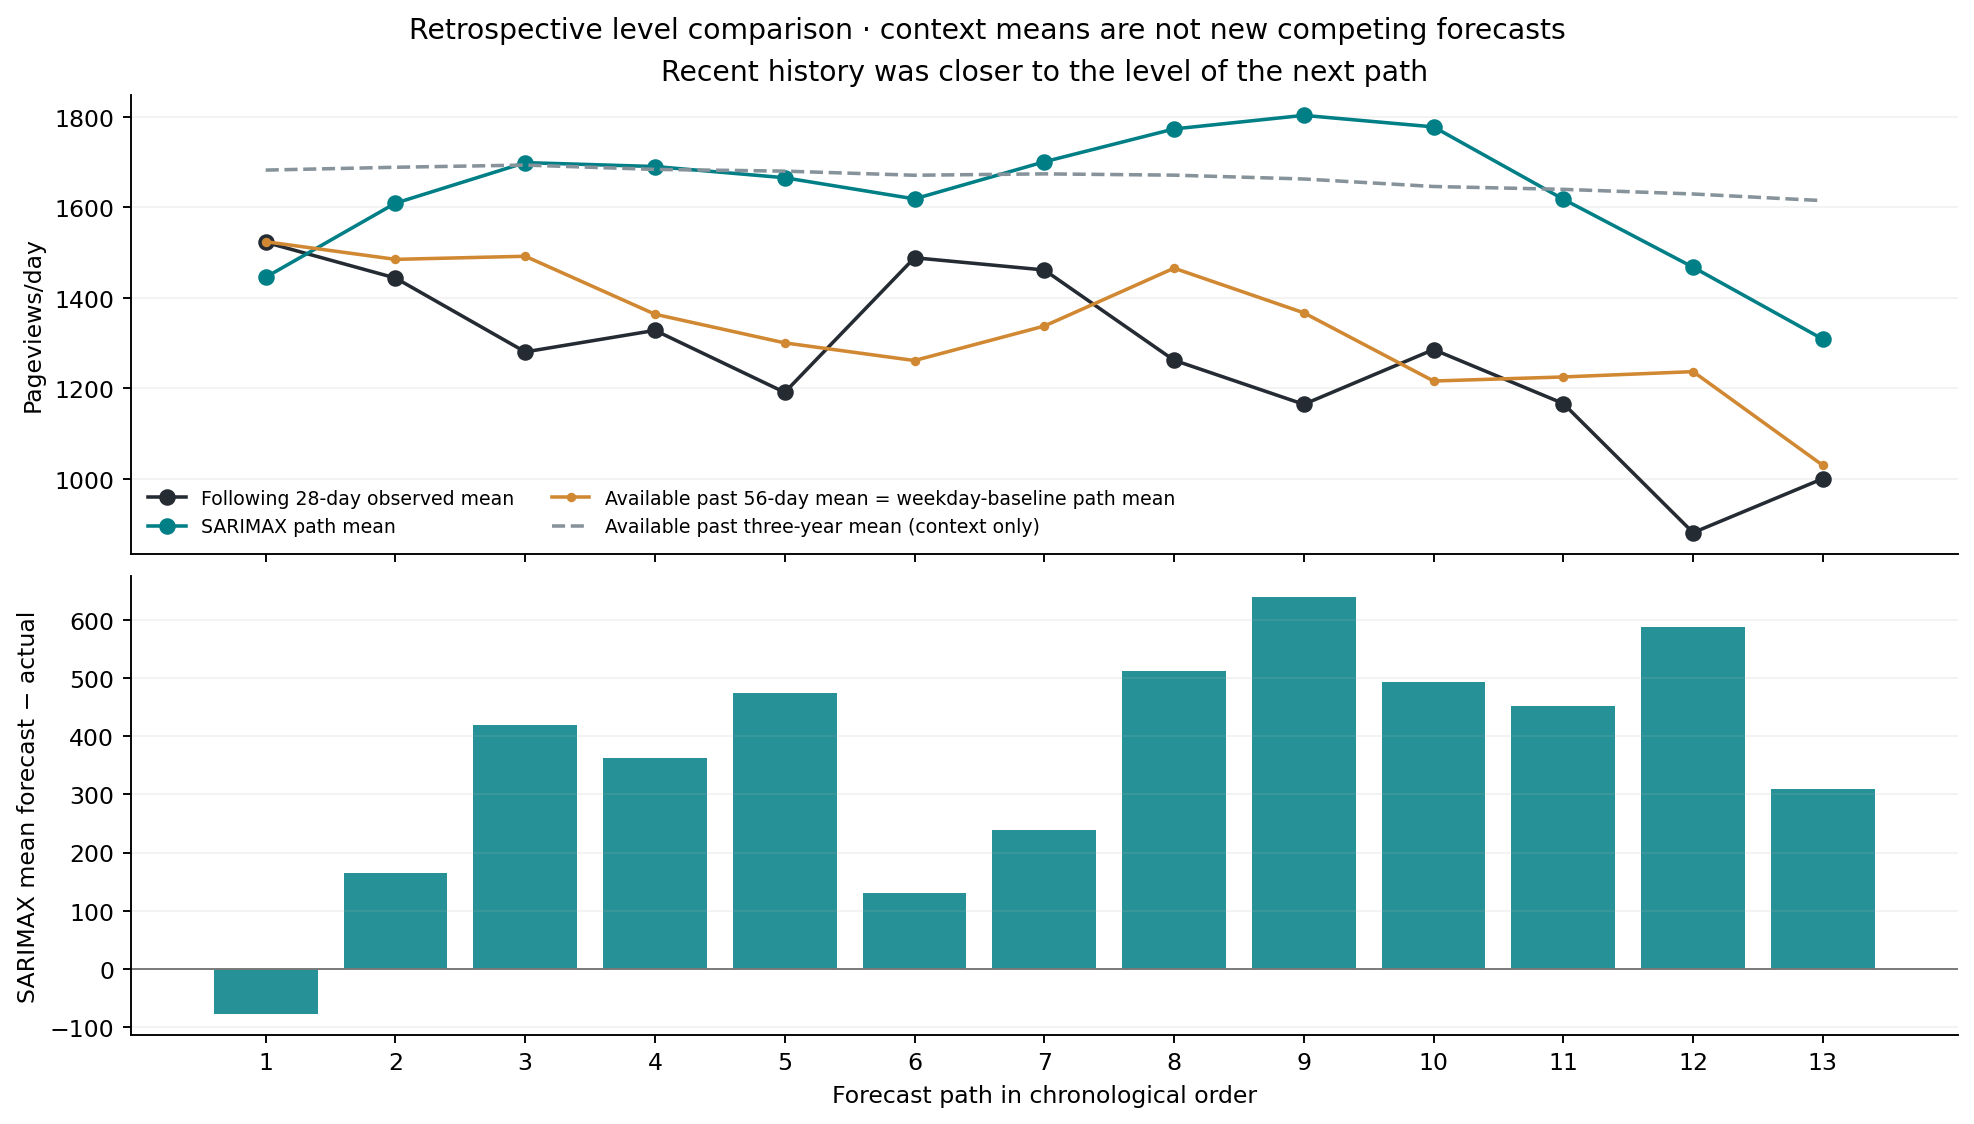

Figure 5. Available recent levels, original forecast levels and realized means on every original final path.


In [17]:
sarima_final = original_final.loc[original_final.family == 'sarimax']
original_diagnostics = saved.metrics(sarima_final)
top10_share = np.sort(np.abs(sarima_final.prediction - sarima_final.actual))[-10:].sum() / sarima_final.absolute_error.sum()
assert original_diagnostics['overprediction_days'] == 326
display(pd.Series({**original_diagnostics, 'top_10_error_share': top10_share}))
levels = pd.read_csv(P3 / 'path_level_diagnostics.csv').loc[lambda d: d.family == 'sarimax']
closer = (np.abs(levels.past56_mean - levels.actual_mean) < np.abs(levels.prediction_mean - levels.actual_mean)).sum()
assert closer == 12
display(Image(filename=str(ROOT / 'figures/diagnostics/09_level_adaptation.png')))
print('Figure 5. Available recent levels, original forecast levels and realized means on every original final path.')

### Why I examined weekly differencing

The near-boundary seasonal MA estimates suggested one hypothesis worth
testing. When `Θ` is near −1, the seasonal MA factor `1 + ΘB⁷` resembles the
weekly differencing factor `1 − B⁷`. Their near-cancellation raises a question
about whether weekly differencing is helping this fitted procedure.

That algebra motivated a matched comparison. It did not establish the cause
of overprediction or prove that `D=0` would forecast better. Initialization,
finite-sample estimation, calendar structure and treatment of the level remain
possible contributors. Raw covariance condition numbers also depend on units.

The [saved failure analysis](docs/research/diagnostics/FORECAST_FAILURE_ANALYSIS.md)
examines errors across the path as well. Every issue is a Sunday, tying target
weekday to horizon modulo seven. A jagged horizon profile therefore cannot
isolate forecast distance from weekday or particular calendar events.

I used these diagnostics to formulate bounded follow-up questions, while
keeping the original final result intact.


## 9. Can a more adaptive level improve the forecast?

The recent-level comparison and the differencing hypothesis led to Phase 4:
**retrospective post-evaluation research** on the already inspected year.
A separately locked protocol limited the comparisons. This is **not a new untouched test**.
I investigated six candidates alongside both baselines.

### Three ways to respond to the diagnostics

- **ETS(A,N,A) and ETS(A,Ad,A):** both use additive errors, a local level,
  seven-day additive seasonality and three-year histories. The second adds
  an additive damped trend, reducing trend extrapolation with forecast
  distance. States update through the available history at each issue;
  neither model sees actual counts inside its future 28-day path.
- **Matched SARIMAX `D=0` and `D=1`:** both center and standardize each
  training history, invert predictions back to counts, and share order
  `(1,0,1)`, seasonal MA(1), Fourier `K=2` and L-BFGS `maxiter=500`.
  Centering and inversion preserve a nonzero level for `D=0`. Seasonal
  differencing is the controlled change within this pair. Either arm
  differs from the original raw-count, `maxiter=200` procedure in several
  respects.
- **Matched raw-target and correction LightGBM:** both use the same 17
  past/calendar/horizon features, expanding histories, 300 trees, seven
  leaves, L1 loss and seed 42. Only the training label changes. The
  correction learner predicts departures from the origin-specific weekday
  baseline instead of learning the complete traffic level.

### What a correction label means

For historical issue `S` and step `h`, the label is
`r[S,h] = y[S+h−1] − b[S,h]`, where `b[S,h]` uses observations only through
`S − 2`. At a new issue `O`, the prediction is
`max(0, b[O,h] + predicted_r[O,h])`. Negative correction labels are retained.

The saved example below starts on **September 28, 2025**. On that date, the
available baseline is **1,753.75** and the actual is **1,577**, giving a label
of **−176.75**. On October 2, actual traffic exceeds the baseline, so the
label is **+101**. The learner needs to accommodate both directions.

All 28 outcomes in this illustrative training path end by the specified
**October 31** cutoff. Each historical issue uses its own earlier baseline;
substituting the current issue's baseline for old labels would misrepresent
the information those cases had available. This example reconstructs labels,
without fitting a correction model in the notebook.


In [18]:
def weekday_forecast(y, issue):
    cutoff = pd.Timestamp(issue) - pd.Timedelta(days=2)
    recent = y.loc[:cutoff].iloc[-56:]
    assert len(recent) == 56 and recent.index[-1] == cutoff
    targets = pd.date_range(issue, periods=28)
    means = recent.groupby(recent.index.dayofweek).mean()
    return means.reindex(targets.dayofweek).to_numpy()

S = pd.Timestamp('2025-09-28')
C = pd.Timestamp('2025-10-31')
targets = pd.date_range(S, periods=28)
assert targets[-1] <= C
b_S = weekday_forecast(full_y, S)
correction_labels = full_y.loc[targets].to_numpy() - b_S
assert np.isfinite(correction_labels).all()
display(pd.DataFrame({'target': targets, 'available_baseline': b_S,
                      'actual': full_y.loc[targets].to_numpy(), 'correction_label': correction_labels}).head())

,target,available_baseline,actual,correction_label
0,2025-09-28,1753.750,1577,-176.750
1,2025-09-29,1742.375,1327,-415.375
2,2025-09-30,1698.875,1443,-255.875
3,2025-10-01,1763.625,1457,-306.625
4,2025-10-02,1765.000,1866,101.000


### Separate selection, calibration and retrospective roles

The six candidates and two baselines were fixed before real candidate fitting.
The stage table below reports their MAE over four different populations:

| Stage | Scored paths | Target dates | Role |
|:---|---:|:---|:---|
| Earlier development | 12 | November 5, 2023, to October 5, 2024 | Compare the fixed recipes on earlier history |
| Point selection | 7 | November 3, 2024, to May 17, 2025 | Choose the point procedure |
| Interval calibration | 4 | June 15, 2025, to October 4, 2025 | Set the selected procedure's interval offsets |
| Retrospective comparison | 13 | November 2, 2025, to October 31, 2026 | Examine the already inspected original final year |

The first preflight identified an eighth selection path whose final label
would be unavailable at the first calibration cutoff.
[Amendment 01](provenance/protocols/retrospective_followup/AMENDMENT_01.md)
removed that path from selection scoring **before any real candidate fit**,
retaining it as an observation block. The original protocol and failed
preflight remain recorded. All **216 candidate fits plus 72 baseline paths**
then completed without fallback.

On the seven point-selection paths, the **weekday mean wins with MAE
318.005**, ahead of raw LightGBM (**324.530**) and correction LightGBM
(**330.144**). That rule selected the baseline before calibration scoring.
The correction also loses to its raw-target control in earlier development
and calibration, so its later advantage was not consistent across stages.

The second table ranks this follow-up’s retrospective results and includes RMSE, MASE,
signed error and November-masked MAE. Correction LightGBM leads that Phase 4
MAE ranking, while the weekday mean remains the earlier-selected procedure.
Scores across stage columns concern different dates and conditions; their
changes do not isolate forecast degradation.


In [19]:
p4_summary = pd.read_csv(P4 / 'summary.csv')
stage_order = ['development', 'selection', 'calibration', 'retrospective']
stage_mae = p4_summary.loc[p4_summary.population == 'all'].pivot(index='id', columns='stage', values='mae')
display(stage_mae[stage_order].round(3))
point_selection = json.loads((P4 / 'point_selection.json').read_text())
assert point_selection['selected_id'] == 'weekday_mean'

retro = p4_summary.loc[(p4_summary.stage == 'retrospective') & (p4_summary.population == 'all')].copy()
masked = p4_summary.loc[(p4_summary.stage == 'retrospective') & (p4_summary.population != 'all')].set_index('id')
retro['masked_mae'] = retro.id.map(masked.mae)
display(retro.sort_values('mae')[['id', 'mae', 'rmse', 'mase', 'signed_error', 'masked_mae']].round(3))

stage,development,selection,calibration,retrospective
id,,,,
ets_damped,754.511,423.417,462.700,240.765
ets_level,753.735,423.655,462.759,241.132
lgbm_correction,488.303,330.144,395.306,236.533
lgbm_raw,467.029,324.530,320.037,252.357
sarimax_d0,445.054,352.077,255.152,451.948
sarimax_d1,476.738,387.230,259.272,365.562
weekday_mean,548.568,318.005,354.069,238.733
weekly_naive,863.054,423.485,462.411,251.852


,id,mae,rmse,mase,signed_error,masked_mae
18,lgbm_correction,236.533,312.224,0.566,51.239,230.926
22,weekday_mean,238.733,308.367,0.570,63.751,231.057
16,ets_damped,240.765,322.447,0.576,47.706,235.316
17,ets_level,241.132,322.938,0.576,47.977,235.715
23,weekly_naive,251.852,359.826,0.602,28.440,249.155
19,lgbm_raw,252.357,312.309,0.606,110.582,244.909
21,sarimax_d1,365.562,418.334,0.871,274.450,372.206
20,sarimax_d0,451.948,505.073,1.085,379.910,466.298


### What the matched comparisons reveal

The `D=0` SARIMAX has lower MAE in the earlier stages, but its retrospective
MAE is **451.948**, versus **365.562** for `D=1`: approximately **86.39
views/day worse**. Its MA roots are farther from the boundary, yet its later
forecasts are less accurate. Figure 6 therefore challenges the simple idea
that removing seasonal differencing would fix the original failure.

This is evidence about the standardized matched pair. The newer `D=1`
procedure does not replace the frozen original SARIMAX result, because its
preparation and optimization settings also differ from the original recipe.

The ETS arms come close to the baseline: retrospective MAE is **240.765**
with damped trend and **241.132** without it, compared with **238.733** for
the weekday mean. Neither improves on the baseline's RMSE, and damping
changes MAE only slightly.

All eight Phase 4 procedures have positive retrospective mean signed error. Weekly naive
has the smallest mean overprediction, **+28.44 views/day**, yet its MAE is
higher than the weekday mean's. Bias and absolute error capture different
properties; reducing one does not necessarily reduce the other.


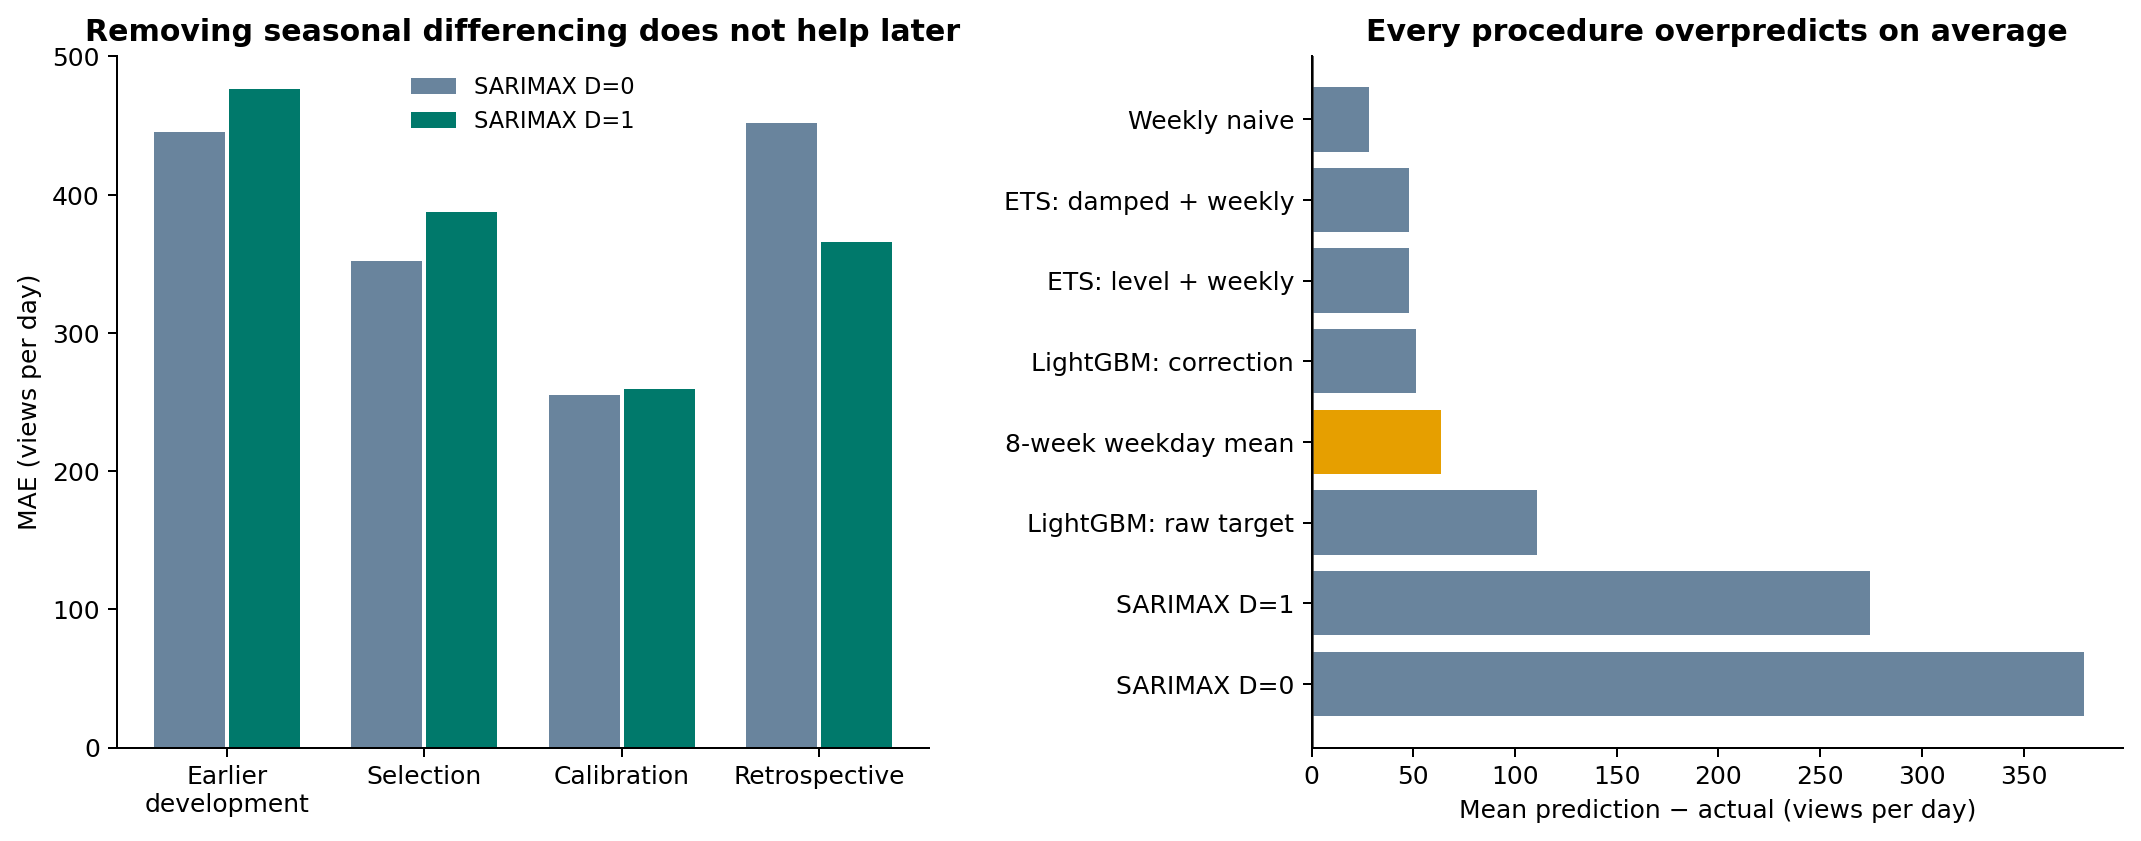

Figure 6. Controlled D=0/D=1 comparison and retrospective signed errors; the original model is a separate procedure.


In [20]:
display(Image(filename=str(ROOT / 'figures/retrospective_followup/03_differencing_and_bias.png')))
print('Figure 6. Controlled D=0/D=1 comparison and retrospective signed errors; the original model is a separate procedure.')

### How much did learning a baseline correction add?

Correction LightGBM improves retrospective MAE by **6.27%** over its matched
raw-target control. Against the stronger weekday baseline, the gain is only
**2.20 views/day**, or **0.92%**. Its RMSE is worse (**312.22 versus 308.37**),
and correction wins only **seven of 13 paired paths**.

Figure 7 displays all those path differences. Negative values favor the
correction and positive values favor the baseline. A small pooled advantage
can coexist with substantial variation across occasions. These dependent
paths do not supply a probability that the correction is the better procedure.

Under the **same predefined November 2025 target-score mask**, correction MAE
is **230.926**, versus **231.057** for the baseline: approximately **0.13
views/day**. The displayed percentages below retain the extra precision:
**0.921287%** over all targets and **0.056861%** under the mask, conventionally
rounded to **0.92%** and **0.06%**.

The mask re-scores unchanged predictions on 335 days, pooling daily errors.
November observations remain available to later training histories. It shows
how sensitive the observed advantage is to this scoring population, without
identifying why.

This follow-up consequently nominated the correction for future confirmation.
It did not independently validate a replacement for the weekday mean. Its
unfavorable earlier-stage results, worse retrospective RMSE and very small
masked gain remain part of that judgment.

That point-forecast comparison still left the interval question open. Phase 4
evaluated the uncertainty of its selected weekday reference separately from
the correction challenger.


retrospective_MAE_improvement_percent       0.921287
November_sensitivity_improvement_percent    0.056861
dtype: float64

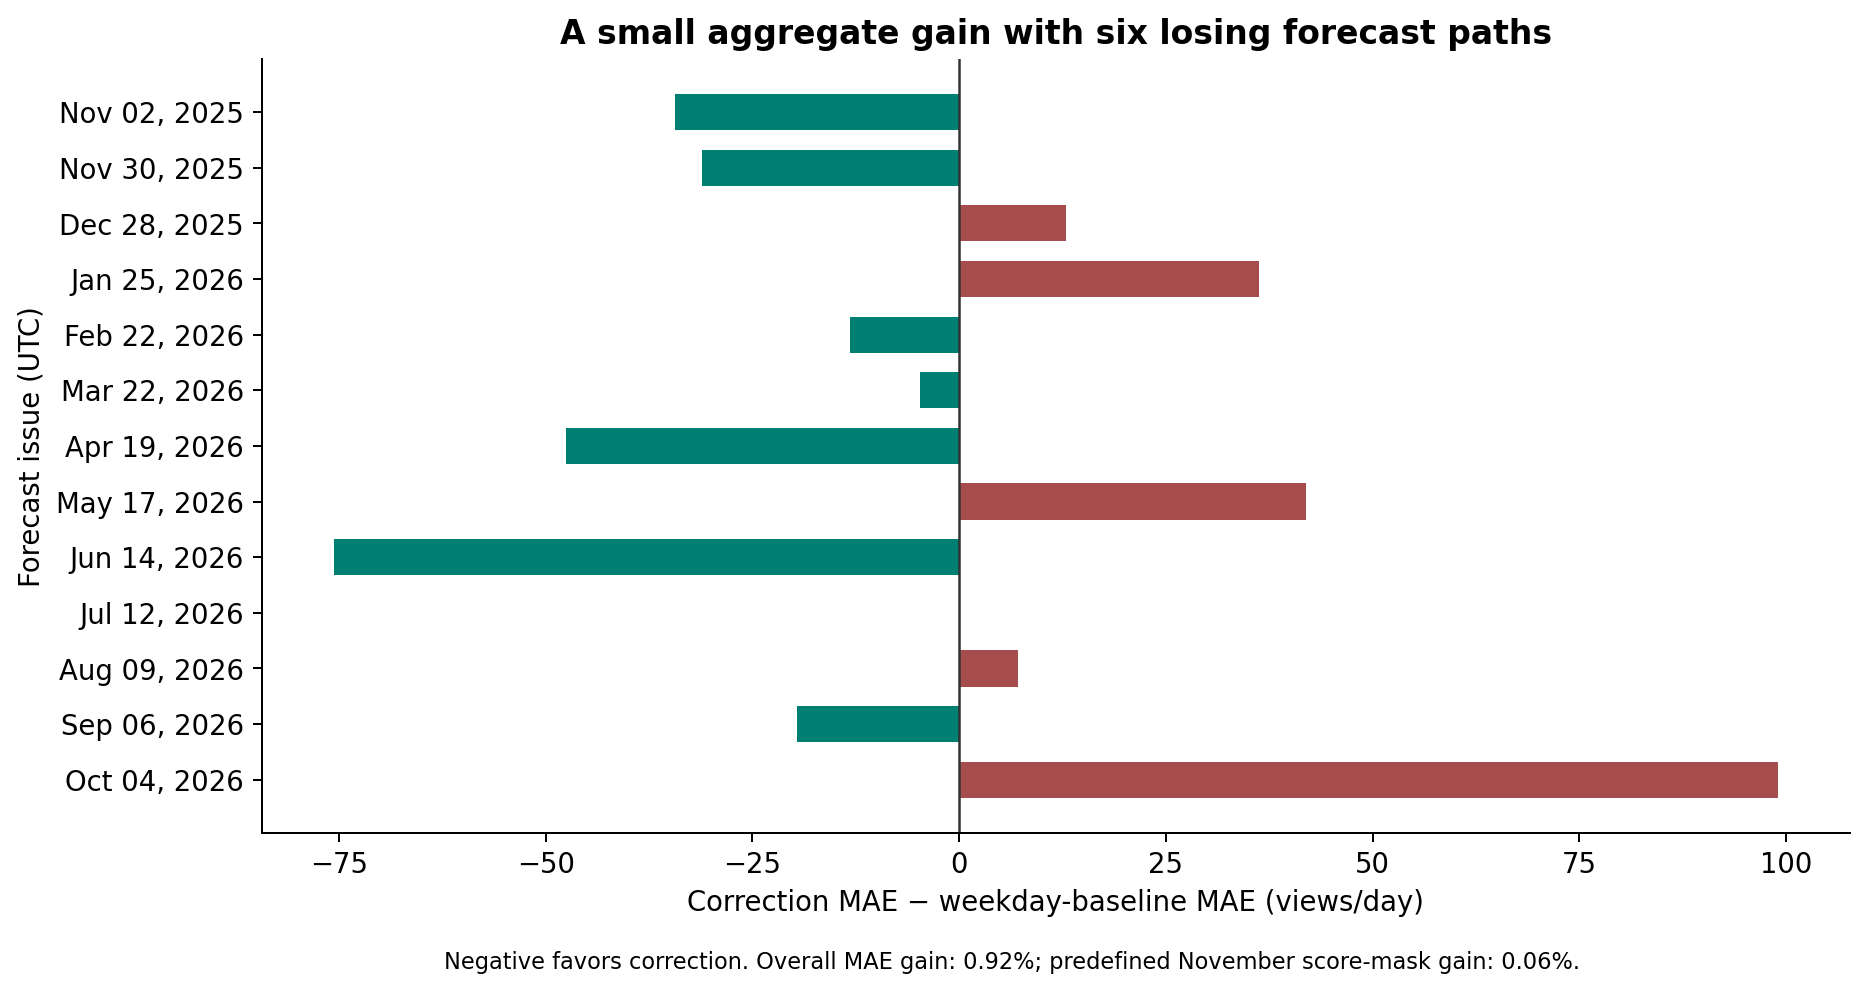

Figure 7. All 13 correction-minus-baseline path MAE differences. Negative favors correction; paths are dependent.


In [21]:
correction = extension.loc[(extension.stage == 'retrospective') & (extension.id == 'lgbm_correction')]
reference = extension.loc[(extension.stage == 'retrospective') & (extension.id == 'weekday_mean')]
mask_november = lambda d: d.loc[~d.date.str.startswith('2025-11-')]
gain = 100 * (1 - saved.metrics(correction)['mae'] / saved.metrics(reference)['mae'])
masked_gain = 100 * (1 - saved.metrics(mask_november(correction))['mae'] / saved.metrics(mask_november(reference))['mae'])
assert round(gain, 2) == .92 and round(masked_gain, 2) == .06
display(pd.Series({'retrospective_MAE_improvement_percent': gain,
                   'November_sensitivity_improvement_percent': masked_gain}))
display(Image(filename=str(ROOT / 'figures/retrospective_followup/04_correction_paired_paths.png')))
print('Figure 7. All 13 correction-minus-baseline path MAE differences. Negative favors correction; paths are dependent.')

## 10. Reading coverage together with width

Point accuracy leaves a separate question: how useful are the uncertainty
bands? Phase 4's point-selection rule chose the weekday mean, which was also
the requested baseline, so it evaluates **one interval procedure**. These
bands belong to that baseline. The correction challenger's intervals have
**not been evaluated**.

Four calibration paths supply **112 signed errors**, defined here as
`r = actual − prediction`. This sign is the reverse of the earlier diagnostic
error definition. One-indexed order statistics **11 and 102** give offsets
**−518.375 and +624.5**. Bounds are
`[max(0, p − 518.375), max(0, p + 624.5)]`. The asymmetric offsets remain
fixed; retrospective errors do not update them.

The first table below compares observed coverage, width and misses over the
same 364 dates:

- **Original SARIMAX:** coverage **44.78%**, mean width **816.57**, with
  190 outcomes below the lower bound and 11 above the upper bound.
- **Retrospective weekday baseline:** coverage **95.88%**, mean width
  **1,142.88**, with two outcomes below and 13 above.

The baseline contains more outcomes but is substantially wider. Coverage
above 80% does not establish accurate nominal calibration, and narrower
bands are not useful if they miss too often.

The **80% interval score** weighs both concerns:
`width + 10 × max(lower − actual, 0) + 10 × max(actual − upper, 0)`.
Lower is better. Its observed value falls from **1,867.19** for the original
SARIMAX to **1,252.95** for the baseline. Both the point model and calibration
rule change, so this comparison cannot isolate the interval method's effect.

Figure 8 and the final row also distinguish daily from complete-path
containment. Only **three of 13 paths**, or **23.08%**, contain all 28 actual
outcomes within the baseline bands. Pointwise nominal coverage did not promise
that stronger outcome.

Selection and calibration are separated within Phase 4, but the broader
investigation already knew this year. Four calibration paths, dependent
errors, pooled horizons and changing conditions leave no asserted
distribution-free guarantee. I read the reported rates as empirical results
for this retrospective population.


,procedure,days,coverage,mean_width,below,above,interval_score80
0,Original SARIMAX,364,0.448,816.573,190,11,1867.189
1,Phase 4 weekday baseline (retrospective),364,0.959,1142.875,2,13,1252.951


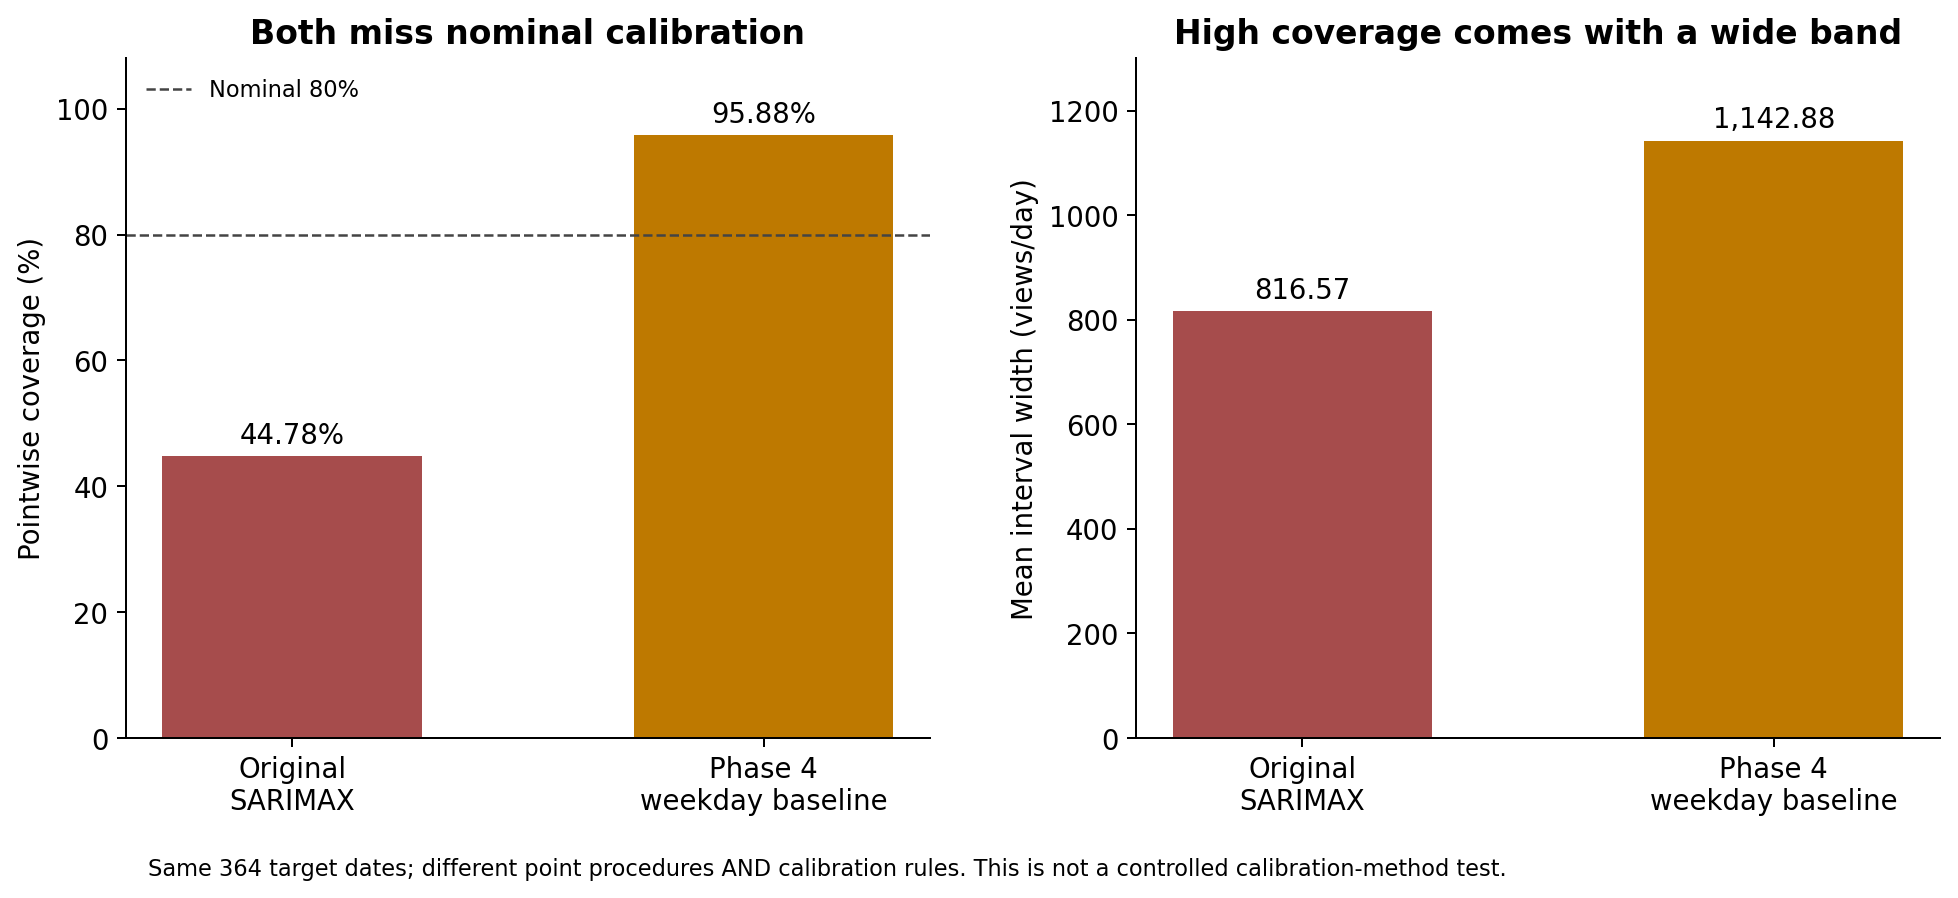

Figure 8. Coverage and width on the same 364 dates; the point model and calibration method both change.


,id,paths,path_coverage
42,weekday_mean,13.0,0.230769


In [22]:
interval_comparison = pd.DataFrame([
    {'procedure': 'Original SARIMAX', **saved.interval_metrics(sarima_final)},
    {'procedure': 'Phase 4 weekday baseline (retrospective)', **saved.interval_metrics(reference)}])
display(interval_comparison.round(3))
display(Image(filename=str(ROOT / 'figures/retrospective_followup/05_interval_diagnostics.png')))
print('Figure 8. Coverage and width on the same 364 dates; the point model and calibration method both change.')
path_coverage = pd.read_csv(P4 / 'interval_metrics.csv')
display(path_coverage.loc[(path_coverage.population == 'all') &
    (path_coverage.group_type == 'simultaneous_complete_paths'), ['id', 'paths', 'path_coverage']])

## 11. Checkpoint: what the original investigation established

Before adding pretrained models, I had reached three findings. SARIMAX won
the original development comparison, then persistently overpredicted the
later year's traffic. The eight-week weekday mean gave a much stronger
reference than its simplicity might suggest. The adaptive follow-up's best
retrospective MAE came from correction LightGBM, but its **0.92%** gain fell
to **0.06%** under the November scoring sensitivity and came with worse RMSE.
The weekday mean remained that follow-up's earlier-selected procedure.

The musical cases made parts of the traffic history more interpretable, while
the event ledger did not provide enough eligible advance-known episodes for
predictive features. The interval comparisons also left a separate problem:
the original SARIMAX band undercovered, the later baseline band overcovered,
and the correction had no evaluated intervals.

**At the November 5, 2026 research snapshot, no future forecasts had been
issued and no genuinely unseen future paths had been completed.** The
correction's nomination and confirmation plan belong to that recorded stage;
they were not independent validation of its apparent improvement.

Those findings led to a further question: could patterns learned across other
time series improve this same forecasting task? I first check the preserved
original and follow-up records below, then introduce the separately documented
foundation-model extension in Section 13. The overall conclusions follow that
extension, so they can address the complete body of evidence.


## 12. Checking the records before the extension

The next output checks the original experiment and adaptive follow-up:
**651 cached procedure-origin records**, **18,228 daily predictions**,
**73 recomputed summary rows**, and **72 reconstructed delayed-baseline
paths**. The cache count combines 324 development records, 39 original
final-evaluation records, and 288 follow-up records. Baseline evaluations
count as procedure-origin records without requiring optimizer fits.

The historical-manifest table reports which source records are included in
this selected GitHub package. `full_historical_archive_verified=False`
indicates that omitted working-archive files are not verified here. It does
not contradict a passing check on the included files.

The saved **zero optimizer fits** and **zero fresh future paths** distinguish
verification from new forecasting evidence. These checks read the existing
records and import no statistical or boosting fitting engine. The later
foundation-model records have their own verification at the end of the notebook.

The [reproduction guide](docs/reproducibility.md) documents the workflows.
This notebook does not refit models. Full research sources, chronology and
data attribution are collected in Section 15, after the complete results
and conclusions.


In [23]:
verification = saved.verify()
display(pd.Series({k: verification[k] for k in (
    'status', 'cached_origin_records_verified', 'daily_predictions_verified',
    'summary_rows_recomputed', 'delayed_baseline_paths_reconstructed',
    'new_optimizer_fits', 'fresh_future_paths')}))
historical = integrity.historical_status()
display(pd.DataFrame([{k: (len(v) if isinstance(v, list) else v) for k, v in row.items()}
                     for row in historical]))
print('Historical manifests are preserved; this delivery verifies its documented subset, not omitted archive files.')
assert not any(name.split('.')[0] in {'statsmodels', 'lightgbm', 'prophet'} for name in sys.modules)
print('No statistical or boosting fitting engine was imported by this notebook.')
print('Complete: saved results verified; no fitting, tuning, interval recalibration or new experiment.')

status                                  passed
cached_origin_records_verified             651
daily_predictions_verified               18228
summary_rows_recomputed                     73
delayed_baseline_paths_reconstructed        72
new_optimizer_fits                           0
fresh_future_paths                           0
dtype: object

,historical_manifest,retained_bytes_verified,documented_delivery_changes,previously_superseded_presentations,omitted_archive_files_not_verified,full_historical_archive_verified
0,protocol/freeze_manifest.json,29,0,0,13,False
1,phase1/freeze_manifest.json,351,0,0,26,False
2,phase2/freeze_manifest.json,55,0,0,16,False
3,phase3/freeze_manifest.json,19,2,0,24,False
4,phase4/freeze_manifest.json,325,1,0,24,False


Historical manifests are preserved; this delivery verifies its documented subset, not omitted archive files.
No statistical or boosting fitting engine was imported by this notebook.
Complete: saved results verified; no fitting, tuning, interval recalibration or new experiment.


## 13. A new question: could pretrained forecasting models add more?

The preceding checkpoint leaves the weekday mean as a demanding reference.
I then tested a different source of forecasting ability: models pretrained
across large collections of other time series. The question remained the same:
how much could a fixed procedure add while respecting the 28-day task and
its observation delay?

This extension compares **Chronos-2** and **TimesFM 2.5 (200M)** with the saved
weekday mean, weekly naive, original SARIMAX and LightGBM correction. It is a
**new retrospective experiment**, performed after I had examined the final
year. It does not replace the original selection result or provide an untouched
confirmation sample.

I fixed one recipe per model before new inference: **1,024 observed days**, no
fine-tuning, no context-length search, no event inputs and no related series.
Both use CPU float32 inference, one thread and seed 42. The
[protocol](provenance/foundation_models/protocol.json) and
[implementation lock](provenance/foundation_models/protocol_lock.json) record
the settings, input hashes and exact checkpoint revisions before inference.
The [extension guide](docs/foundation_models.md) documents reproduction.

### What “zero-shot” establishes here

No foundation-model weights were fitted to Buckethead within this project. That does not
establish an unseen article or absence of pretraining overlap. The official
[TimesFM card](https://huggingface.co/google/timesfm-2.5-200m-pytorch) lists
Wikimedia pageviews through November 2023 alongside other sources. The first
original tuning path overlaps that cutoff month. The
[Chronos-2 report](https://arxiv.org/html/2510.15821v1) also lists Wiki among
pretraining datasets.

Exact Buckethead membership and the coverage of every training component
remain unverified. Older shared history is different from evaluated-target
overlap; this audit does not certify contamination-free evaluation. These are
modern fixed-checkpoint backtests, and some historical issues precede the
models' availability.

The following cells read the completed, cached inference. Running the notebook
does not download model weights or call either foundation model.

In [24]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image

FM_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / 'provenance/foundation_models/protocol.json').exists())
sys.path.insert(0, str(FM_ROOT / 'src'))
import foundation_analysis as fm
FM_RESULTS = FM_ROOT / 'results/foundation_models'
fm_protocol = json.loads((FM_ROOT / 'provenance/foundation_models/protocol.json').read_text())
fm_audits = pd.DataFrame(json.loads((FM_RESULTS / 'inference_audit.json').read_text()))
display(pd.DataFrame([
    {'model': fm.LABELS[key], 'checkpoint': value['repository'],
     'revision': value['revision'], 'context_days': fm_protocol['context_length'],
     'point': 'native median', 'fine_tuning': False}
    for key, value in fm_protocol['models'].items()
]))
display(pd.Series(json.loads((FM_RESULTS / 'run_summary.json').read_text()),
                  name='Completed foundation-model inference'))

,model,checkpoint,revision,context_days,point,fine_tuning
0,"Chronos-2, zero-shot",amazon/chronos-2,29ec3766d36d6f73f0696f85560a422f50e8498c,1024,native median,False
1,"TimesFM 2.5, zero-shot",google/timesfm-2.5-200m-pytorch,1d952420fba87f3c6dee4f240de0f1a0fbc790e3,1024,native median,False


status                                                                             passed
models                                                              [chronos2, timesfm25]
origin_records                                                                         74
bridge_predictions                                                                   2146
scored_predictions                                                                   2072
optimizer_fits                                                                          0
fallbacks                                                                               0
new_future_paths                                                                        0
context_length_search                                                               False
fine_tuning                                                                         False
protocol_sha256          8f1da97d722a5442ae9c3d23b2cb191f969809b4102c1e0c2a8ace1a5f47e5ea
completed_

### 13.1. Preserve the delay, then inspect earlier-period behavior

At issue `O`, each model receives observations through `O − 2`. Its **29-step
bridge** starts on the unobserved day `O − 1`; only the remaining 28 targets
are scored. Earlier actuals inside a path cannot update it. I retain all 29 raw
quantile triplets in the caches, with context-date and value hashes.

Both recipes use the **native median** as the point forecast for MAE, RMSE and
MASE. Quantiles 0.1 and 0.9 supply the nominal 80% pointwise band. A shared
postprocessing rule sorts the three quantiles within each date, then clips at
zero. Raw values and repair counts remain recorded; neither model needed a
fallback. This common interface keeps the target and timing aligned. Architectures,
pretraining corpora and history policies remain differences between the full
procedures.

The first table below checks that all **74 model-origin records** used 1,024
context values. The second reports **12 legacy tuning**, **12 selection** and
**13 retrospective paths** for each model. These names identify existing target
populations; no configuration was chosen from their new scores.

On the original selection period, the two models have almost identical MAE:
**316.75 for Chronos-2 and 316.72 for TimesFM**. Both exceed the original
selected SARIMAX's **303.98**, while staying below the weekday mean's **326.66**.
Their later gains therefore did not amount to leading every historical stage.

In [25]:
display(fm_audits.groupby('model_id').agg(
    origin_records=('origin_id', 'size'),
    min_context_days=('context_rows', 'min'),
    max_context_days=('context_rows', 'max'),
    first_context_end=('context_end', 'min'),
    last_context_end=('context_end', 'max'),
))
fm_stage = pd.read_csv(FM_RESULTS / 'stage_metrics.csv')
display(fm_stage.pivot(index='model_id', columns='stage', values='mae')
        [['tuning', 'selection', 'retrospective']].round(3))
fm_forecasts = pd.read_csv(FM_RESULTS / 'forecasts.csv')
assert len(fm_forecasts) == 2146 and fm_forecasts.scored.sum() == 2072
assert fm_forecasts.loc[fm_forecasts.scored].groupby(['model_id', 'origin_id']).size().eq(28).all()

,origin_records,min_context_days,max_context_days,first_context_end,last_context_end
model_id,,,,,
chronos2,37,1024,1024,2023-11-03,2026-10-02
timesfm25,37,1024,1024,2023-11-03,2026-10-02


stage,tuning,selection,retrospective
model_id,,,
chronos2,425.127,316.752,211.380
timesfm25,429.342,316.725,199.399


### 13.2. Comparing the same 364 later targets

The comparison below uses the original **13 final-year paths**, with matching
targets and the original common MASE scale. Reference predictions are loaded
unchanged from the earlier experiments.

**TimesFM's MAE is 199.40 views/day**, compared
with **238.73** for the eight-week weekday mean:
an observed reduction of **16.48%**.
**Chronos-2 reaches 211.38**, a reduction of
**11.46%**. Both also have
lower retrospective RMSE than the weekday reference and the correction model.

TimesFM's mean signed error is **-5.57**,
compared with **+20.17** for Chronos-2
and **+63.75** for the weekday mean.
That is a smaller average level mismatch than the original SARIMAX's
**+361.91**. It does not make every error small or balanced: TimesFM still
overpredicts on **226 of 364 days**.
The mean sign can conceal a different mix of frequent and large errors.

These are observed differences between complete recipes, including distinct
training data and history policies. They do not isolate which architectural
choice produced the advantage or independently establish performance on new
outcomes.

,model_id,mae,rmse,mase,signed_error,mae_improvement_percent
3,timesfm25,199.399,286.493,0.476,-5.567,16.476
0,chronos2,211.380,291.687,0.504,20.167,11.457
1,lgbm_correction,236.533,312.224,0.566,51.239,0.921
4,weekday_mean,238.733,308.367,0.570,63.751,0.000
5,weekly_naive,251.852,359.826,0.602,28.440,-5.495
2,original_sarimax,437.776,489.017,1.050,361.907,-83.375


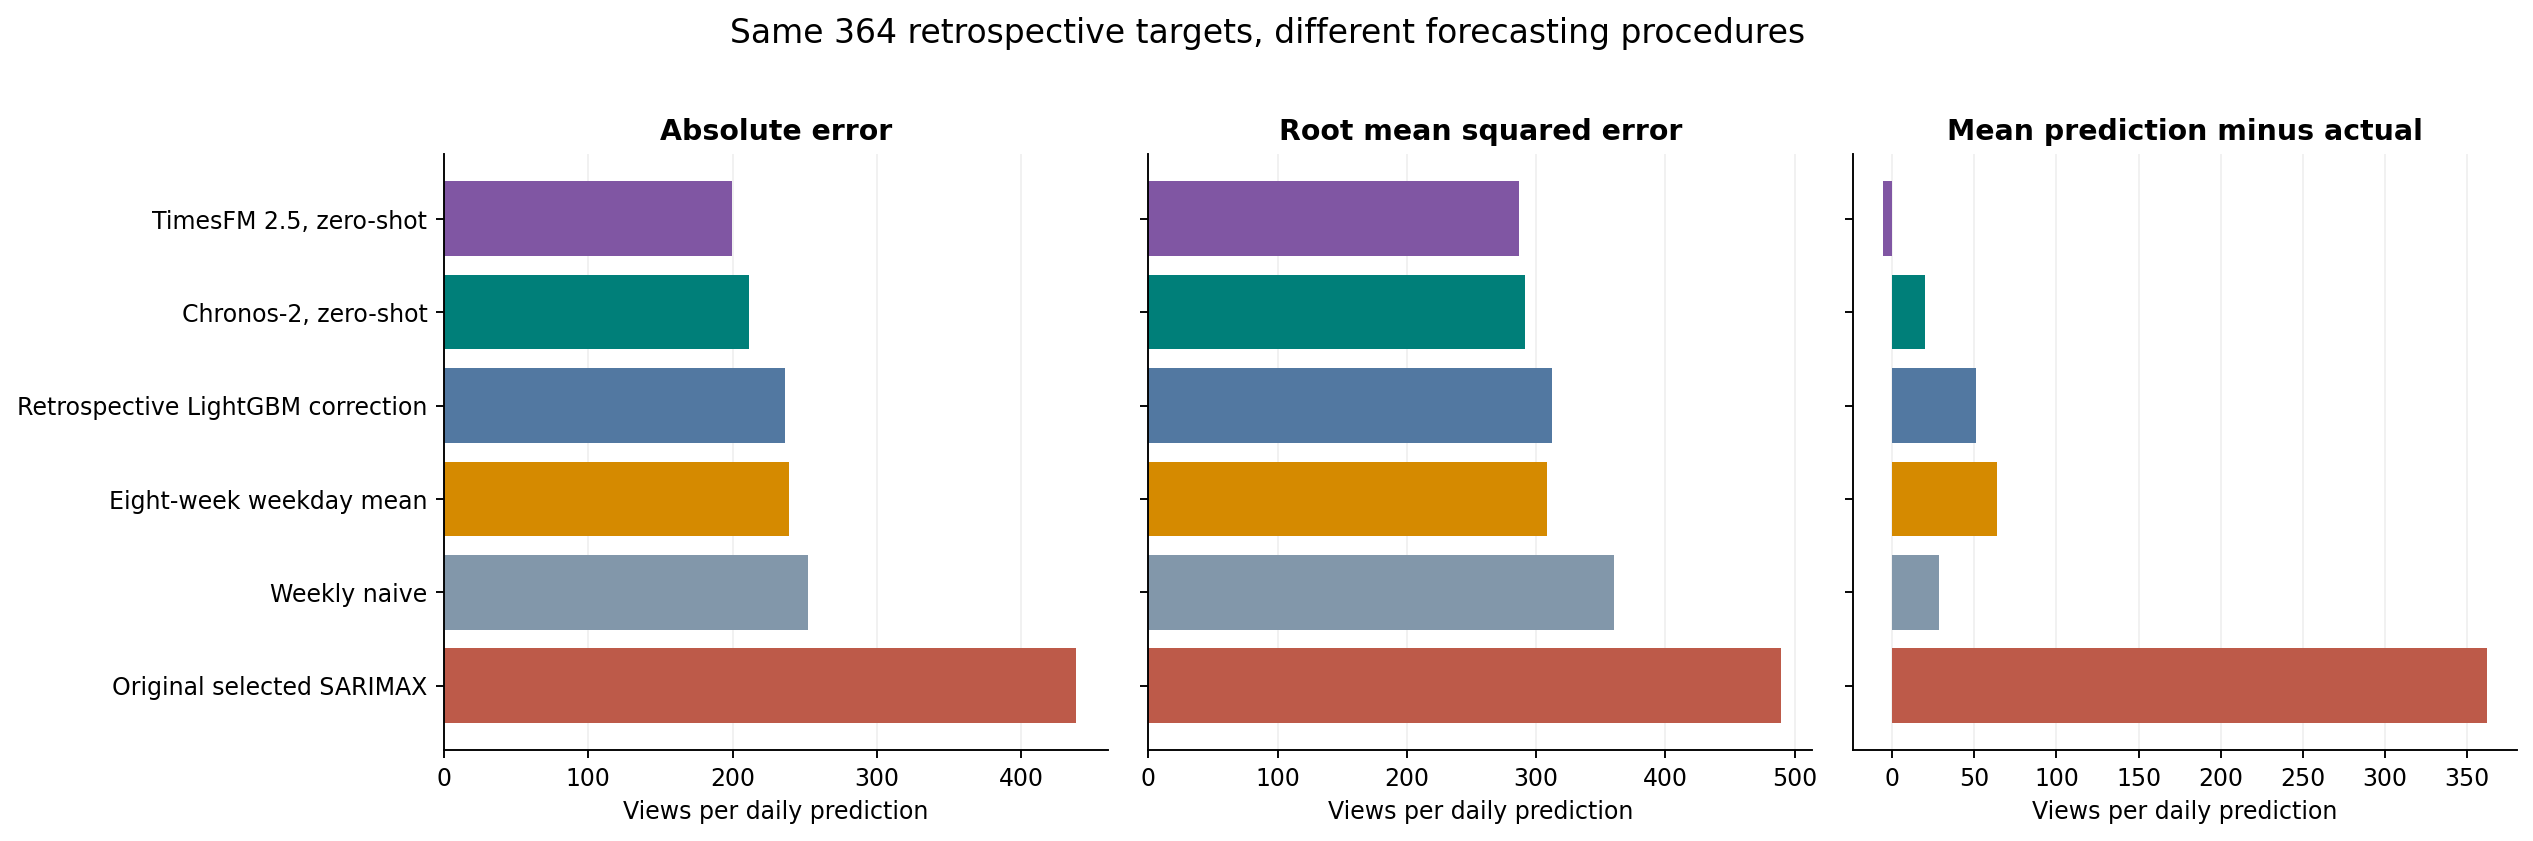

Figure F1. MAE, RMSE and signed error on the same 364 retrospective dates. Foundation models use median predictions; the earlier procedures retain their saved point forecasts.


In [26]:
fm_comparison = pd.read_csv(FM_RESULTS / 'comparison.csv')
fm_primary = fm_comparison.loc[fm_comparison.population == 'all'].sort_values('mae')
display(fm_primary[['model_id', 'mae', 'rmse', 'mase', 'signed_error',
                    'mae_improvement_percent']].round(3))
display(Image(filename=str(FM_ROOT / 'figures/foundation_models/01_point_comparison.png')))
print('Figure F1. MAE, RMSE and signed error on the same 364 retrospective dates. '
      'Foundation models use median predictions; the earlier procedures retain their saved point forecasts.')

### 13.3. Does the advantage depend on November or particular paths?

Applying the existing November 2025 score mask leaves **335 targets** from
the same predictions. TimesFM's MAE becomes
**189.94**, versus the weekday mean's
**231.06**, a
**17.80%** reduction.
Chronos-2 reaches **203.11**, a
**12.10%** reduction.
These gains persist under the predefined mask, unlike the earlier correction's
very small masked advantage. November observations still enter later contexts
when available; this check does not identify the measurement incident's effect.

TimesFM beats the weekday mean on **nine of 13 full paths**; Chronos-2 does
so on **eight**. Figure F2 retains every path difference, including losses.
The pooled masked scores weight retained days, while an unweighted mean of
masked path MAEs would answer a different question.

The horizon panel has 13 outcomes per step. Sunday issue dates still tie
horizon modulo seven to weekday, and the paths share histories. I do not
interpret this small, dependent comparison as a population-superiority test.

,model_id,days,mae,rmse,mae_improvement_percent
9,timesfm25,335,189.940,268.150,17.795
6,chronos2,335,203.109,275.999,12.096
7,lgbm_correction,335,230.926,293.722,0.057
10,weekday_mean,335,231.057,296.323,0.000
11,weekly_naive,335,249.155,358.866,-7.833
8,original_sarimax,335,450.883,494.857,-95.139


,mean_path_difference,paths_won,paths_lost
model_id,,,
chronos2,-27.353,8,5
lgbm_correction,-2.199,7,6
original_sarimax,199.043,2,11
timesfm25,-39.334,9,4
weekday_mean,0.000,0,0
weekly_naive,13.119,7,6


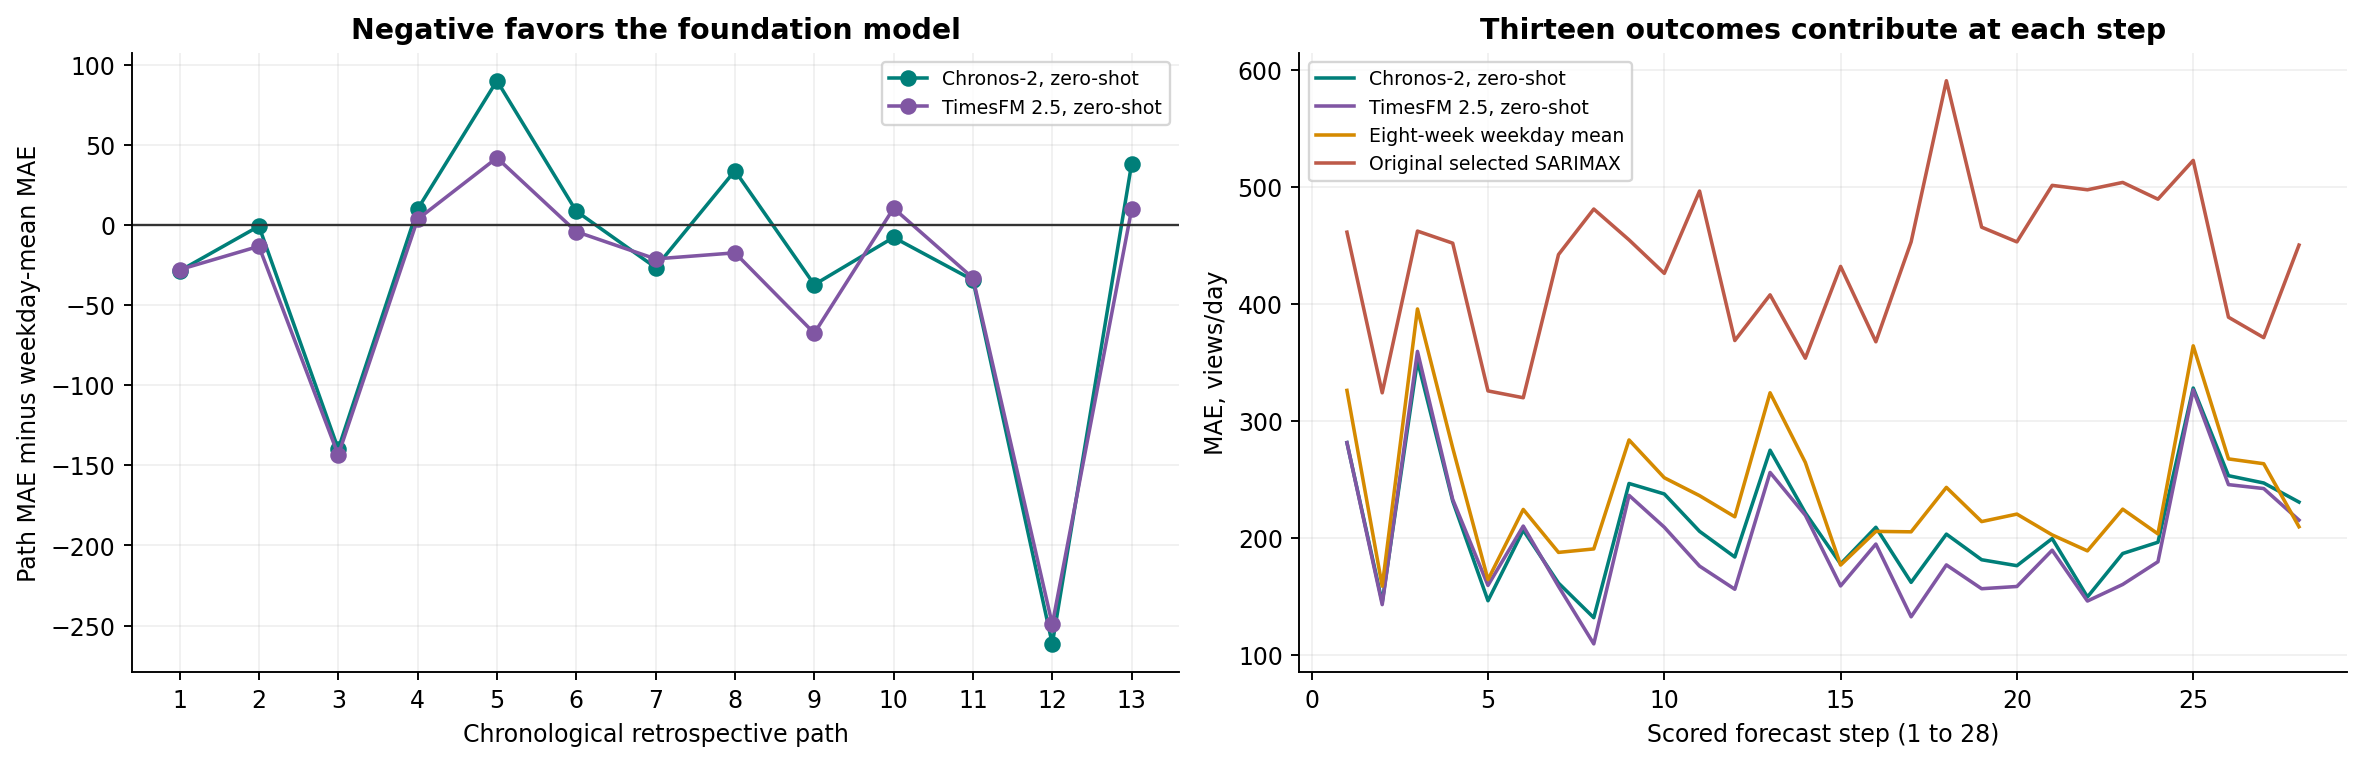

Figure F2. Paired path MAE differences and horizon profiles. Negative differences favor the foundation model; all 13 paths are shown.


In [27]:
display(fm_comparison.loc[fm_comparison.population == 'exclude_november_2025',
    ['model_id', 'days', 'mae', 'rmse', 'mae_improvement_percent']].sort_values('mae').round(3))
fm_paired = pd.read_csv(FM_RESULTS / 'paired_paths.csv')
fm_pair_summary = fm_paired.loc[fm_paired.population == 'all'].groupby('model_id').difference.agg(
    mean_path_difference='mean', paths_won=lambda x: int((x < 0).sum()),
    paths_lost=lambda x: int((x > 0).sum()))
display(fm_pair_summary.round(3))
display(Image(filename=str(FM_ROOT / 'figures/foundation_models/02_paired_and_horizon.png')))
print('Figure F2. Paired path MAE differences and horizon profiles. '
      'Negative differences favor the foundation model; all 13 paths are shown.')

### 13.4. Native uncertainty still needs a separate answer

The point-accuracy improvements raise the same uncertainty question asked
of the earlier procedures. Without local residual calibration, the nominal
**80% native bands** cover
**75.55%** of retrospective outcomes
for TimesFM and **70.33%** for Chronos-2.
Their mean clipped widths are **702.40**
and **713.24 views**, respectively. Both
undercover, even though their point forecasts improve on the seasonal reference.

The weekday mean's Phase 4 residual band covers **95.88%**, with width
**1,142.88**. The new native bands are narrower, so coverage must be read
alongside width and missed-outcome penalties. The observed 80% interval score
is **1041.03 for TimesFM** and
**1089.20 for Chronos-2**, compared with
**1,252.95** for the weekday band; lower is better.

These comparisons change the point model and interval construction together.
They do not isolate a calibration-method effect. The correction learner has
no evaluated intervals and receives none from the baseline.

The next output reports pointwise and complete-path containment separately.
An 80% pointwise band does not promise that all 28 targets will be contained.
I leave the native bands unchanged, without using these errors to repair their
coverage or claiming a distribution-free guarantee.

,model_id,days,coverage,mean_width,below,above,interval_score80
0,chronos2,364,0.703,713.237,78,30,1089.198
1,original_sarimax,364,0.448,816.573,190,11,1867.189
2,timesfm25,364,0.755,702.396,62,27,1041.034
3,weekday_mean,364,0.959,1142.875,2,13,1252.951


,complete_paths,all_targets_contained,complete_path_coverage
model_id,,,
chronos2,13,1,0.076923
timesfm25,13,1,0.076923


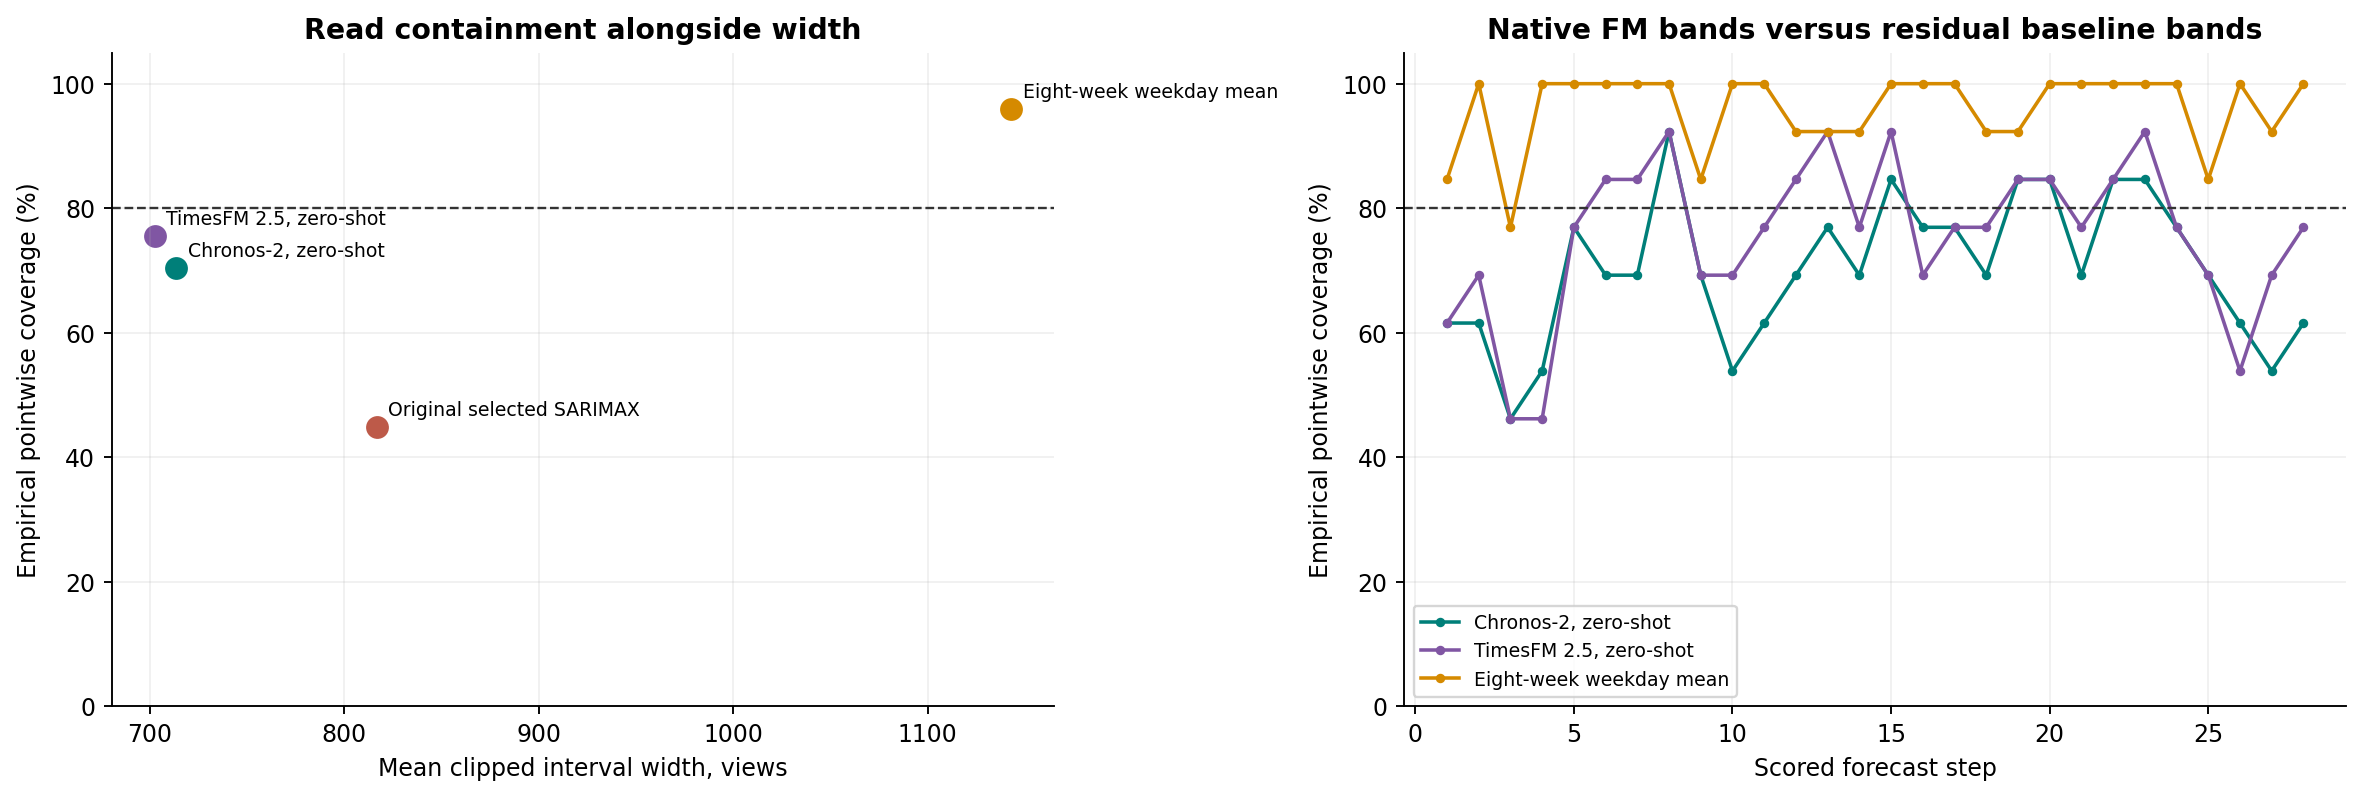

Figure F3. Empirical coverage, clipped width and coverage by step. Native foundation-model bands and locally calibrated baseline bands are different procedures.


In [28]:
fm_intervals = pd.read_csv(FM_RESULTS / 'interval_metrics.csv')
display(fm_intervals.loc[fm_intervals.population == 'all',
    ['model_id', 'days', 'coverage', 'mean_width', 'below', 'above', 'interval_score80']].round(3))
fm_scored = fm_forecasts.loc[fm_forecasts.scored & (fm_forecasts.stage == 'retrospective')].copy()
fm_scored['hit'] = (fm_scored.actual >= fm_scored.lower) & (fm_scored.actual <= fm_scored.upper)
display(fm_scored.groupby(['model_id', 'issue']).hit.all().groupby('model_id').agg(
    complete_paths='size', all_targets_contained='sum', complete_path_coverage='mean'))
display(Image(filename=str(FM_ROOT / 'figures/foundation_models/03_native_intervals.png')))
print('Figure F3. Empirical coverage, clipped width and coverage by step. '
      'Native foundation-model bands and locally calibrated baseline bands are different procedures.')

### 13.5. Inspecting the paths and recording the cost

Figure F4 shows the **first three retrospective paths in chronological order**,
including the November measurement-sensitive targets. The examples were not
selected for low errors. The black trace is actual traffic, the dashed trace
is the weekday mean, and the shaded areas are each foundation model's native
80% pointwise bands. The paired plot above retains the other ten paths.

The execution table records checkpoint-loading time, inference time and peak
process memory on this Mac, using one CPU thread. Loading a checkpoint is
separate from predicting one path. Those machine-specific measurements do not
establish a universal speed comparison with the older fitting recipes.

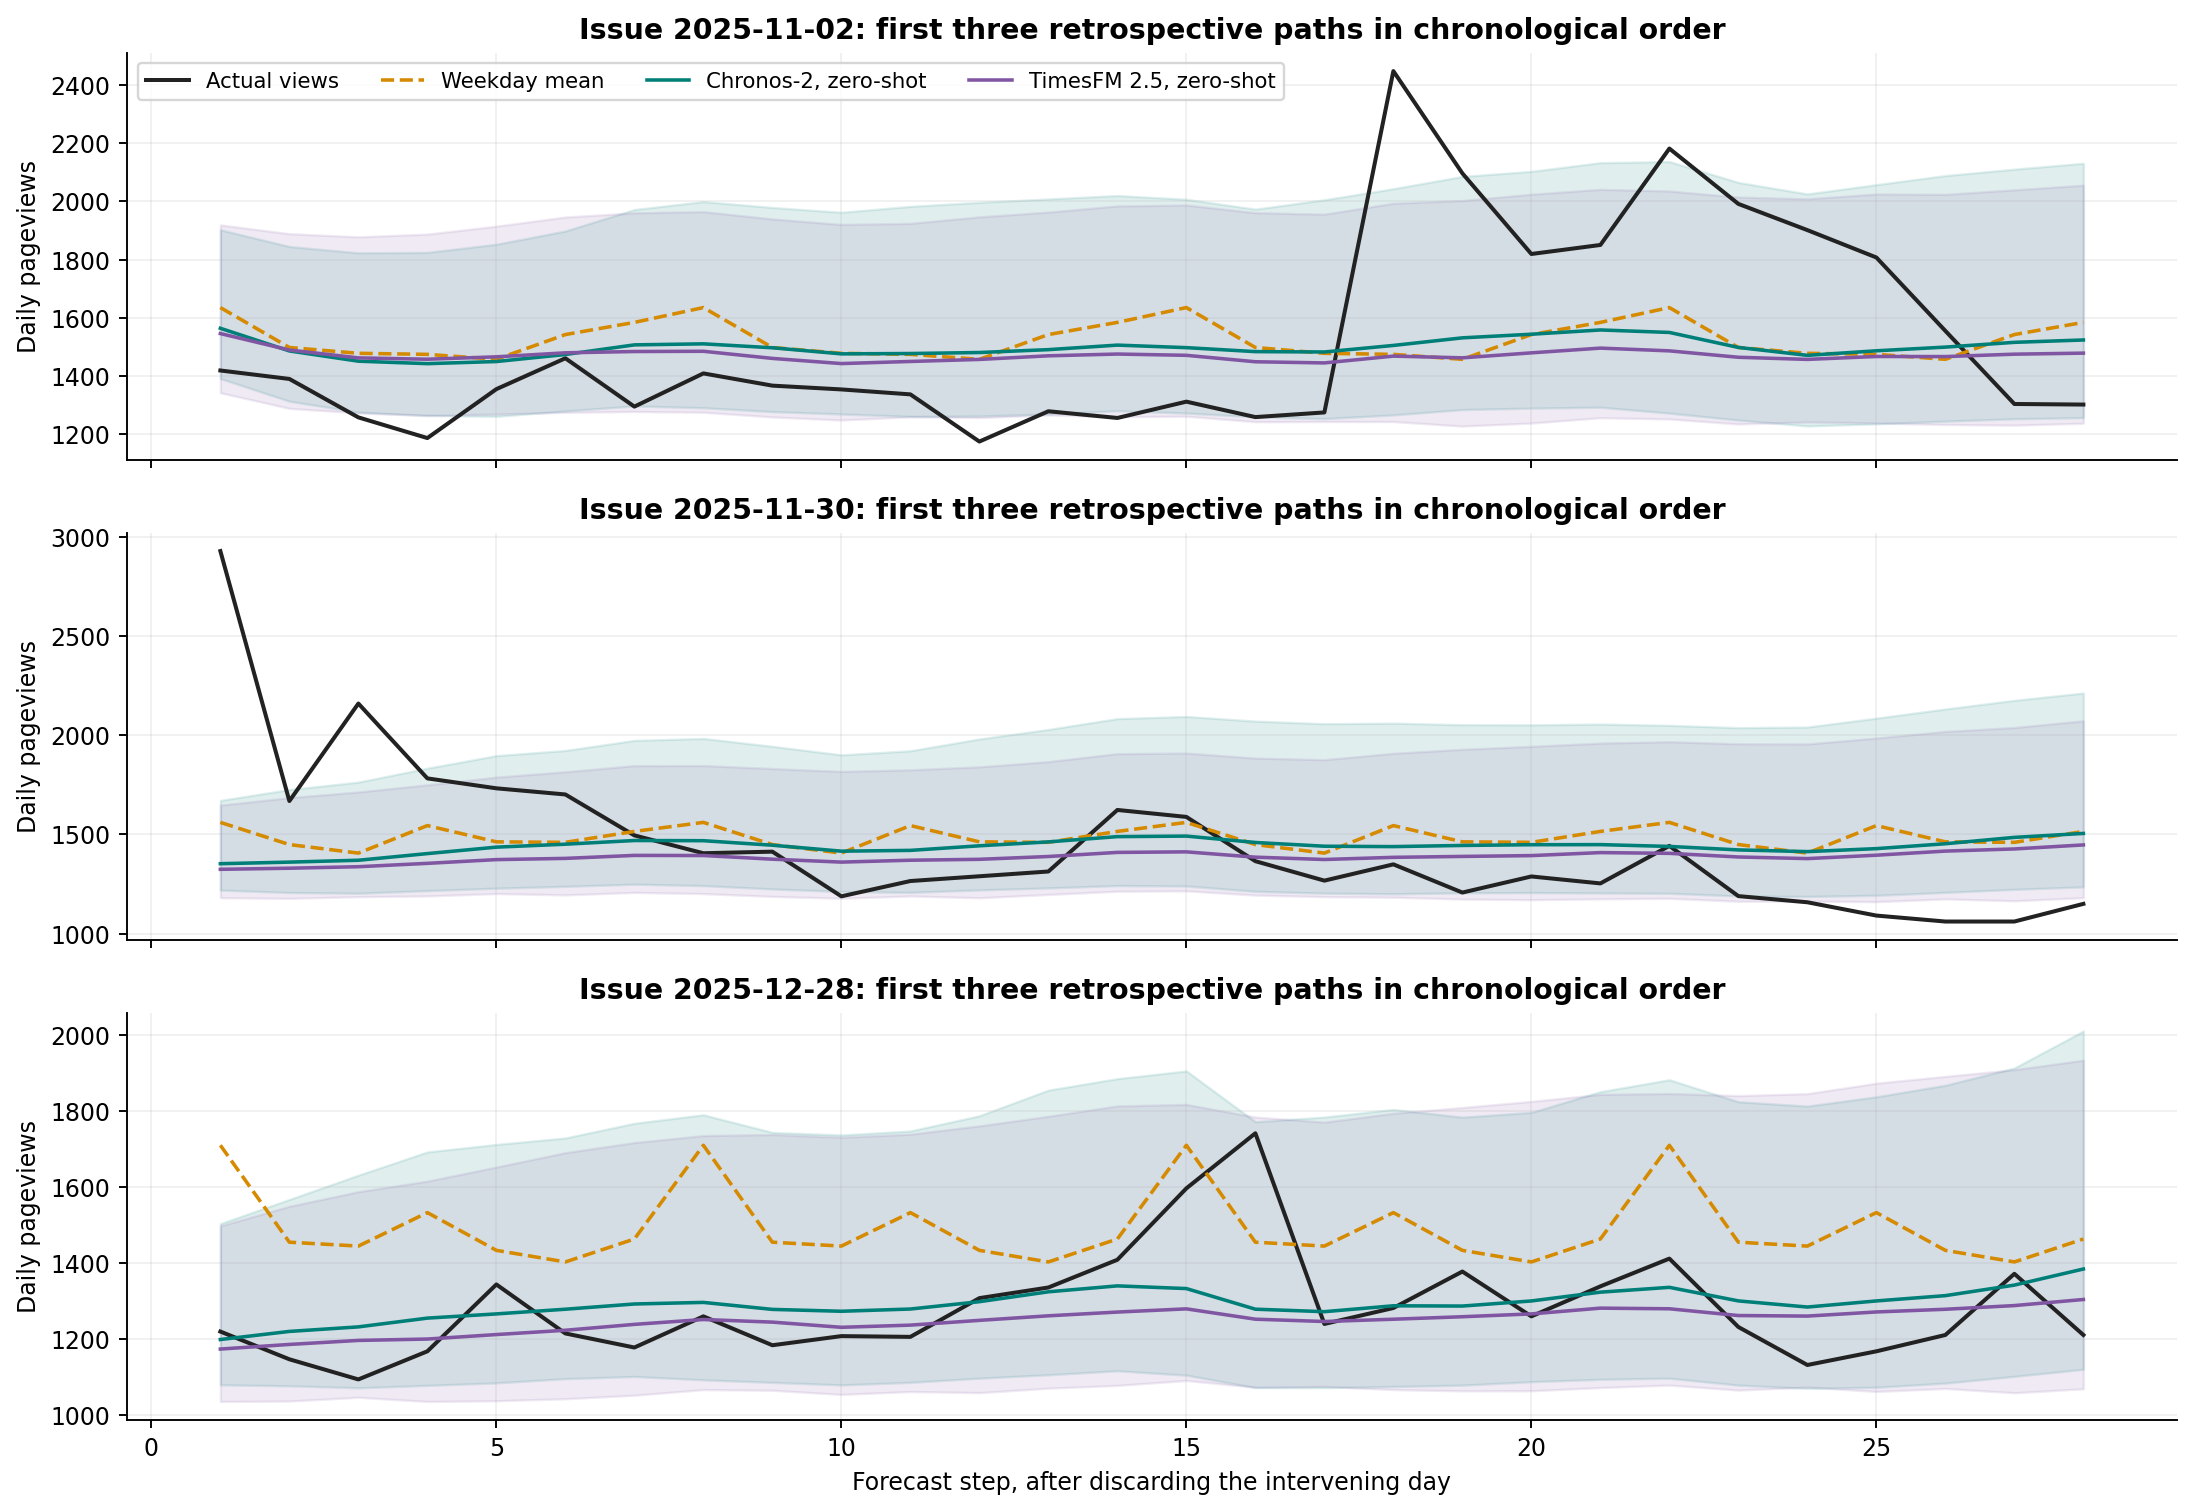

Figure F4. The first three retrospective paths, with median forecasts and native 80% bands. These examples illustrate the saved results, not newly issued future forecasts.


,model_id,paths,loading_seconds,mean_inference_seconds,peak_process_GiB,warnings,quantile_crossing_rows,negative_quantiles_clipped
0,chronos2,37,7.565,0.062,0.859,0,0,0
1,timesfm25,37,1.724,0.119,1.940,0,0,0


In [29]:
display(Image(filename=str(FM_ROOT / 'figures/foundation_models/04_first_three_paths.png')))
print('Figure F4. The first three retrospective paths, with median forecasts and native 80% bands. '
      'These examples illustrate the saved results, not newly issued future forecasts.')
fm_runtime = []
for fm_key in fm_protocol['models']:
    fm_execution = json.loads((FM_RESULTS / (fm_key + '_execution.json')).read_text())
    fm_subset = fm_audits.loc[fm_audits.model_id == fm_key]
    fm_runtime.append({'model_id': fm_key, 'paths': len(fm_subset),
        'loading_seconds': fm_subset.loading_seconds.iloc[0],
        'mean_inference_seconds': fm_subset.inference_seconds.mean(),
        'peak_process_GiB': fm_execution['peak_process_memory_bytes'] / 2**30,
        'warnings': int(fm_subset.warnings.map(len).sum()),
        'quantile_crossing_rows': sum(x['crossing_rows'] for x in fm_subset.repairs),
        'negative_quantiles_clipped': sum(x['negative_quantiles'] for x in fm_subset.repairs)})
display(pd.DataFrame(fm_runtime).round(3))

## 14. What the complete investigation established

I began with curiosity about Buckethead's music and attention to his Wikipedia
page. The forecasting work made that curiosity more precise: define the
recorded target, fix what is available at issuance, then ask whether each
additional model earns its place against a strong reference.

The three research stages answer different parts of that question:

| Stage | What the saved comparison established |
|:---|:---|
| Original development and evaluation | SARIMAX won development selection but lost to the weekday mean on the later year, with persistent overprediction and poor interval transfer. |
| Adaptive-model follow-up | ETS and matched differencing checks tested specific responses to the diagnostics. Correction LightGBM added a small, sensitive retrospective MAE advantage, while the weekday mean remained the earlier-selected procedure. |
| Foundation-model extension | Fixed TimesFM and Chronos-2 recipes improved later-period MAE by 16.48% and 11.46% against the weekday mean, respectively. Both advantages persisted under the existing November score mask. |

Those results do not retroactively change the original selections. Neither
foundation model led the original selection-period MAE comparison when
evaluated now, and the later year had already informed the wider investigation.
The stronger retrospective results provide a reason for a new confirmation
study, while leaving the original failure and its diagnosis intact.

### Accuracy and uncertainty remain separate findings

TimesFM led the observed later-period MAE and RMSE comparison. Its native 80%
band nevertheless covered **75.55%** of outcomes, while Chronos-2 covered
**70.33%**. The wider Phase 4 baseline band covered **95.88%**. The interval
scores help assess the width-and-miss trade-off, without turning any of those
rates into evidence of reliable nominal calibration. The correction model's
uncertainty remains unevaluated.

The historical musical cases also retain their own role. They identify useful
associations in the traffic history, without establishing causal effects or
supplying the advance-information record needed for forecasting covariates.

### What I would carry into a new study

The evidence concerns one canonical article, one original final year and
dependent paths. Retrieved-history revisions, unverified historical publication
times, the assumed observation buffer, small original search grids and the
follow-ups' retrospective design constrain generalization. Exact article
membership and evaluated-date overlap in foundation-model pretraining remain
unverified. Neither numerical convergence nor a lower observed score settles
the cause of the original SARIMAX bias.

I would freeze a bounded comparison before receiving new outcomes, save
timestamped forecasts and input snapshots, and assess signed error alongside
MAE and RMSE. Any new interval calibration would need its own specified
calibration and evaluation periods. A revised confirmation study would also
document how the foundation-model findings affected the candidate choice;
it should remain separate from Phase 4's already recorded nomination plan.

**The completed foundation extension adds no future forecasts and evaluates
no genuinely unseen future paths.** It improves the retrospective comparison,
while independent confirmation remains the next source of evidence.

For me, the most useful outcome is a clearer connection between each question
and the evidence needed to answer it. Recent weekday history set a demanding
reference. Investigating a failed selection exposed where point forecasts
and intervals broke down. The pretrained models then added a stronger
retrospective result, with uncertainty and validation questions still open.

## 15. Sources, reproducibility and data license

### References and research sources

The links below distinguish general method references from this project's own protocols and implementation. Artist metadata support release editions and dates, not historical advance notice or traffic causation.

- **Pageview measurement:** Wikimedia Foundation, [API reference](https://doc.wikimedia.org/generated-data-platform/aqs/analytics-api/reference/page-views.html) and [pageview definitions](https://doc.wikimedia.org/generated-data-platform/aqs/analytics-api/concepts/page-views.html). The [November 2025 incident report](https://wikitech.wikimedia.org/wiki/Data_Platform/Data_Lake/Data_Issues/2026-06-10_Nov_2025_spike_in_bot_traffic) motivates the predefined score sensitivity, without establishing article-specific contamination.
- **Buckethead release evidence:** series context and numbered installments are linked in the introduction; artist listings for [Dreams Remembered](https://bucketheadpikes.bandcamp.com/album/dreams-remembered), [Sea Above The Sky](https://bucketheadpikes.bandcamp.com/album/sea-above-the-sky) and [Hold Me Forever](https://bucketheadpikes.bandcamp.com/album/hold-me-forever-in-memory-of-my-mom-nancy-york-carroll); the [frozen event ledger](data/research/event_ledger.csv) and [research source assessment](docs/research/data_and_sources/BUCKETHEAD_RESEARCH.md) preserve the wider historical evidence and unresolved dates.
- **Interview chronology and retrospective illustration:** the source links beside historical figure H1 distinguish publisher metadata, a directory's listed episode date, and dated contemporary coverage. The [Stage 3 source register](provenance/sources/interview_sources.json) records verification limits; the [descriptive plan](docs/research/historical_context/DESCRIPTIVE_PLAN.md) fixes the local comparisons without reopening the event ledger.
- **SARIMAX and differencing:** the statsmodels [SARIMAX reference](https://www.statsmodels.org/v0.14.4/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html) and Hyndman & Athanasopoulos, *Forecasting: Principles and Practice*, [ARIMA models](https://otexts.com/fpp3/arima.html). The [Phase 3 analysis](docs/research/diagnostics/FORECAST_FAILURE_ANALYSIS.md) explains the study-specific near-cancellation hypothesis and its limits.
- **ETS:** the statsmodels [ETSModel reference](https://www.statsmodels.org/v0.14.4/generated/statsmodels.tsa.exponential_smoothing.ets.ETSModel.html), including its state-update equations. These versioned statsmodels documentation pages describe 0.14.4; the preserved fitting environment uses 0.14.5, whose actual implementation/configuration is recorded in this project.
- **LightGBM and baseline corrections:** Ke et al. (2017), [LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://proceedings.neurips.cc/paper_files/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html), describes the algorithm. Our origin-specific correction targets and paired controls are defined in section 9 and the [locked Phase 4 engine](src/research/retrospective_followup/engine.py); their empirical benefit is evaluated here, not established by that paper.
- **Forecast evaluation:** Hyndman & Athanasopoulos, [The forecaster's toolbox](https://otexts.com/fpp3/toolbox.html), especially point-forecast accuracy and time-series cross-validation. The [project protocol](provenance/protocols/original/EXPERIMENT.md) specifies the delayed task and common origin-specific MASE scale used here.
- **Prediction intervals:** Gneiting & Raftery (2007), [Strictly Proper Scoring Rules, Prediction, and Estimation](https://sites.stat.washington.edu/raftery/Research/PDF/Gneiting2007jasa.pdf), section 6.2, supports the width-and-miss interval score. The [original uncertainty protocol](provenance/protocols/original/UNCERTAINTY.md) and [Phase 4 protocol](provenance/protocols/retrospective_followup/PROTOCOL_V2.md) specify our actual calibration rules; those rules do not inherit a coverage guarantee from the scoring reference.

- **Foundation models:** the official [Chronos-2 model card](https://huggingface.co/amazon/chronos-2), [Chronos-2 technical report](https://arxiv.org/html/2510.15821v1) and [TimesFM 2.5 model card](https://huggingface.co/google/timesfm-2.5-200m-pytorch) describe the pretrained models and disclosed training sources. The [extension protocol](provenance/foundation_models/protocol.json), [implementation lock](provenance/foundation_models/protocol_lock.json) and [reproduction guide for the extension](docs/foundation_models.md) identify the exact recipes tested here. Published benchmark performance does not establish performance on this project.

### Reproduce the recorded work

The [main reproduction guide](docs/reproducibility.md) distinguishes saved-result
execution, saved-parameter checks and optional fixed-recipe fitting. The
[foundation-model guide](docs/foundation_models.md) separately documents
optional pretrained inference. Running this notebook reads the completed
records, including cached foundation-model quantiles; it performs no model
fitting, fine-tuning or model inference.

Original fitting implementations and their locks retain their bytes. The
execution adapter reconstructs their historical paths and applies the
documented failure policy. Earlier numerical checks reproduced the recorded
cases, without establishing identification or global optimality. The original
environment's NumPy/Matplotlib metadata discrepancy remains in its historical
record. Phase 4 used a consistent separate environment, and the combined
requirements for the foundation extension were installed and checked in a new
Python environment on the existing macOS host. Clean-OS and cross-platform
numerical equivalence remain untested.

### Research chronology and preserved records

Phases 0 and 1 fixed the original task and compared development procedures.
Phase 2 evaluated the selected procedure on the original final year. Phase 3
investigated the errors and historical context, and Phase 4 conducted the
bounded adaptive-model follow-up. The original research snapshot is
**November 5, 2026**, with historical/editorial source checks on **November 6**.
The separately frozen foundation-model extension was completed on
**November 18, 2026**, using the same saved target series ending October 31.
It retrieved no new target observations and issued no prospective forecasts.

The [delivery record](provenance/packaging.json),
[source map](provenance/source_map.json) and
[current manifest](provenance/manifest.json) distinguish included files from
the [historical archive](docs/research_archive.md). Earlier editorial and
execution checks are dated records of their own versions. Hashes support
local integrity checks; they do not establish external preregistration or
analyst blindness.

### Data source and license

Source: **Wikimedia Foundation, [Wikimedia Analytics API](https://doc.wikimedia.org/generated-data-platform/aqs/analytics-api/reference/page-views.html)**. Article: **[Buckethead, English Wikipedia](https://en.wikipedia.org/wiki/Buckethead)**. Period: **July 1, 2015–October 31, 2026**.

The API data are available under **[CC0 1.0 Universal](https://creativecommons.org/publicdomain/zero/1.0/)** and may be reused, modified and redistributed, including commercially. See the [official Wikimedia licensing policy](https://doc.wikimedia.org/generated-data-platform/aqs/analytics-api/documentation/access-policy.html). This independent study is not affiliated with or endorsed by the Wikimedia Foundation.

**CC0 applies to the API data**, not automatically to project code, writing, charts, photographs, album covers, music or external research materials. Those retain their applicable terms. The full statement is in the [project README](README.md#data-source-and-license).

### Final saved-result verification

The last output checks the foundation extension's **74 origin records**,
**2,146 bridge predictions** and **2,072 scored daily predictions**, including
context hashes, the discarded day, common scales and comparison tables.
Section 12 reports the corresponding checks for the earlier experiments.
These are consistency checks on the saved records, with no new forecasting
evidence generated by notebook execution.


In [30]:
display(pd.Series(fm.verify_foundation(), name='Foundation-model saved-result verification'))
assert not any(name.split('.')[0] in {'torch', 'chronos', 'timesfm'} for name in sys.modules)
print('Complete: new inference results verified from caches; no foundation model was loaded by this notebook.')

status                                         passed
procedure_origin_records                           74
bridge_predictions                               2146
scored_predictions                               2072
models                          [chronos2, timesfm25]
optimizer_fits                                      0
fine_tuning                                     False
new_future_paths                                    0
verification_inference_calls                        0
Name: Foundation-model saved-result verification, dtype: object

Complete: new inference results verified from caches; no foundation model was loaded by this notebook.
